# STEP 3 - Score the present value of top entrant firms

Build the **present score** of the main firms of our Quantum Computing Sector: four indicators from PATSTAT, each with its refinements, combined into one ranking and tested for robustness.

In the PW our investment bank asks: **which firms of the sector hold the most valuable patents today?** In Step 3 of the deck we answer with a **present score**: one number per firm, which ranks the firms of our sector.

**Present** means: based on what has **already happened** to the patents (citations received, decisions of the examiners, countries where they are protected).


| Dimension | The question | In the Clarivate ranking | In this notebook (basics) | Lecture |
|---|---|---|---|---|
| **Volume** | How much does the firm invent? | a **gate**: only organizations with at least 100 inventions with a granted patent in 5 years are ranked | share of the sector's families; the gate is `MIN_FAMILIES` | size |
| **Success** | Do the examiners accept its inventions? | inventions with a granted patent ÷ inventions published as applications, last 5 years | granted ÷ filed EP applications | legal |
| **Globalization** | Are they protected in the main markets? | share of inventions with **quadrilateral** families: filed in China, Europe, Japan and the US | number of offices per family | economic |
| **Influence** | Do others build on them? | citations from other organizations, last 5 years, **self-citations excluded** | citations within 5 years ÷ mean of the same priority year | technological |

We rank the firms of **one sector**, so every indicator is relative to that sector.
We analyse one dimenion at a time, always in two parts: 

- **Basics**: the measure of the PW, the one that goes into the score;
- **Refinements**: better or richer versions of the same idea. We pick the ones that fit your sector and say why.

Then we combine the four basic indicators into **one ranking** and we check that the ranking is robust, and finally we show how to bring a refinement into the score. Each **design decision** (window, firms, weights) is justified in the technical appendix of the deck.

## 1. Setup

In [89]:
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sqlalchemy import func, or_, and_

REPO = Path.cwd() if (Path.cwd() / "config").is_dir() else Path.cwd().parent
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))

from stage00_config import load_config
cfg = load_config()

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,                 # applications: families, dates, grant
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS206_PERSON,                # persons: harmonised names and sector
    TLS207_PERS_APPLN,            # person <-> application links (who is applicant)
    TLS209_APPLN_IPC,
    TLS211_PAT_PUBLN,             # publications
    TLS212_CITATION,              # citations between publications, with their origin
    TLS214_NPL_PUBLN,
    TLS215_CITN_CATEG,            # category of each citation (X, Y, A, I...)
    TLS224_APPLN_CPC,             # CPC classification: defines the sector
    TLS228_DOCDB_FAM_CITN,        # citations between DOCDB families
    TLS231_INPADOC_LEGAL_EVENT,   # legal events: refusals, fees paid in each state
    TLS230_APPLN_TECHN_FIELD
)

SECTOR_CPC_PREFIXES = cfg.cpc_prefixes
SECTOR_KEYWORDS = cfg.keywords 
SECTOR_KEYWORD_EXCLUSIONS = cfg.keyword_exclusions
IPR_TYPE = "PI" 
YEAR_MIN = 2000
YEAR_MAX = 2022

ENV = cfg.env
SECTOR_NAME = cfg.sector_name
patstat = PatstatClient(env=ENV)
db = patstat.orm()
print(f"Sector: {SECTOR_NAME} | env: {ENV}")

OUT = Path("outputs/step3")        # the score is saved here for the Magic Quadrant
OUT.mkdir(exist_ok=True)

NAVY, ORANGE, BLUE, GREY, MID, LIGHT = "#002B49", "#EF7B00", "#4F7CA3", "#4A5A6A", "#8A9AAB", "#D9E1E8"
LINES = [NAVY, ORANGE, BLUE, "#7A9A3A", "#A23B72", MID]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left"})
pd.set_option("display.max_colwidth", 45)

Sector: Quantum computing | env: PROD


## 2. The Quantum Computing Sector and its Applicants

- **Unit: the DOCDB family.** One invention is one family, whatever the number of applications it has (EP, divisional applications, US, CN...).
- **Time: the priority year** (`earliest_filing_year`, the date closest to the invention). We read 2000-2022: the whole period serves to follow the shares over time and to choose the window.
  
We extract the global dataset of these families along with their **applicants** (`applt_seq_nr > 0`). This gives us the raw ownership data needed for name harmonization.

In [90]:
def symbol_prefix_condition(symbol_column, codes):
    """OR-condition: the blank-stripped classification symbol starts with one of the codes."""
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))

def keyword_condition(terms, exclusions=()):
    """Any term appears in the title or abstract and no exclusion phrase does (case-insensitive).

    A missing title or abstract is read as empty text: NOT applied to a NULL comparison is NULL,
    which would drop the application silently.
    """
    title = func.lower(func.coalesce(TLS202_APPLN_TITLE.appln_title, ""))
    abstract = func.lower(func.coalesce(TLS203_APPLN_ABSTR.appln_abstract, ""))
    match = or_(*(col.like(f"%{t.lower()}%") for t in terms for col in (title, abstract)))
    if not exclusions:
        return match
    excluded = or_(*(col.like(f"%{x.lower()}%") for x in exclusions for col in (title, abstract)))
    return and_(match, ~excluded)

family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")
by_cpc = (db.query(family_id)
          .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
          .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, SECTOR_CPC_PREFIXES)))

sector_ids = by_cpc
if SECTOR_KEYWORDS:
    by_kw = (db.query(family_id)
             .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
             .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
             .filter(keyword_condition(SECTOR_KEYWORDS, SECTOR_KEYWORD_EXCLUSIONS)))
    sector_ids = by_cpc.union(by_kw)

family_year = func.min(TLS201_APPLN.earliest_filing_year)
families = (
    db.query(TLS201_APPLN.docdb_family_id.label("unit_id"), family_year.label("year"))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE,
            TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .group_by(TLS201_APPLN.docdb_family_id)
    .having(family_year.between(YEAR_MIN, YEAR_MAX))
    .subquery()
)

q_sector = (
    db.query(families.c.unit_id, 
             families.c.year, 
             TLS206_PERSON.psn_id, 
             TLS206_PERSON.psn_name,
             TLS206_PERSON.psn_sector, 
             func.trim(TLS206_PERSON.person_ctry_code).label("ctry"))
    .select_from(families)
    .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == families.c.unit_id)
    .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
    .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0) 
    .distinct()
)

raw_sector = patstat.df(q_sector)
print(f"Extracted {raw_sector['unit_id'].nunique():,} patent families with their respective applicants, priority years {YEAR_MIN}-{YEAR_MAX}")

Extracted 12,306 patent families with their respective applicants, priority years 2000-2022


### 2.1 The time window

Two indicators need **time**: patent offices worldwide take several years to examine and grant an application, and citations arrive over several years. Recent applications are not granted *yet*, and recent families are not cited *yet*: they would look weak only because they are young. 

The chart shows the share of global applications granted today, by priority year. Where the curve drops in recent years, the applications are not worse, just pending.

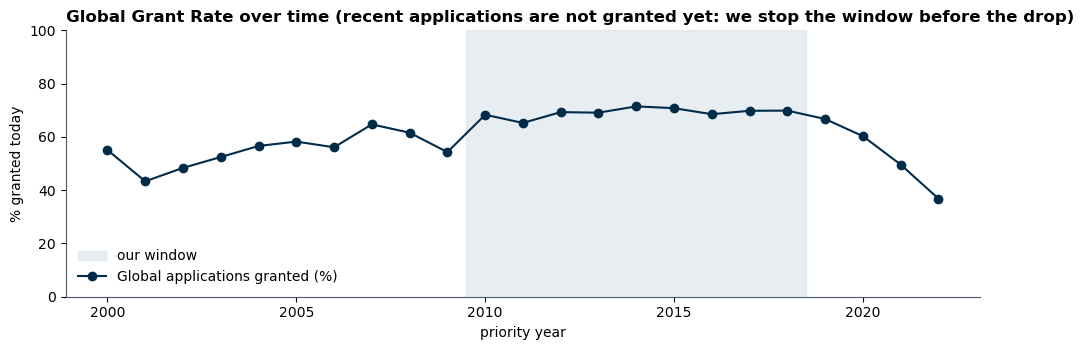

Window 2010-2018: 3,061 families, 7,772 GLOBAL applications


In [91]:
q_apps = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.earliest_filing_year,
        TLS201_APPLN.earliest_publn_year,
        TLS201_APPLN.granted
    )
    .filter(TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .filter(TLS201_APPLN.earliest_filing_year.between(YEAR_MIN, YEAR_MAX))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
)

apps_all = patstat.df(q_apps).drop_duplicates("appln_id")

families_all = (
    apps_all.groupby("docdb_family_id")
          .agg(priority_year=("earliest_filing_year", "min"),
               first_publn_year=("earliest_publn_year", "min"))
          .reset_index()
)


WINDOW = (2010, 2018)       # the priority years we score: see the shaded area

grant_rate = apps_all.groupby("earliest_filing_year").granted.apply(lambda s: (s == "Y").mean())
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(WINDOW[0] - 0.5, WINDOW[1] + 0.5, color=LIGHT, alpha=0.6, label="our window")
ax.plot(grant_rate.index, grant_rate * 100, marker="o", color=NAVY, label="Global applications granted (%)")
ax.set_ylim(0, 100)
ax.set_xlabel("priority year")
ax.set_ylabel("% granted today")
ax.legend(frameon=False, loc="lower left")
ax.set_title("Global Grant Rate over time (recent applications are not granted yet: we stop the window before the drop)")
plt.tight_layout()
plt.show()

apps = apps_all[apps_all.earliest_filing_year.between(*WINDOW)].copy()
families = families_all[families_all.priority_year.between(*WINDOW)].copy()
FAMILIES = [int(f) for f in families.docdb_family_id]
print(f"Window {WINDOW[0]}-{WINDOW[1]}: {len(FAMILIES):,} families, {len(apps):,} GLOBAL applications")

## 3. The firms: who owns which family?

The owners are the **applicants** (`applt_seq_nr > 0` in `TLS207`). A family filed by two firms together counts for **both** of them (*full counting*). We read the owners of the whole period, 2000-2022.

PATSTAT's default `psn_name` merges some spelling variants, but it does **not group different legal entities or subsidiaries of the same multinational together**. To solve this, we apply our harmonisation pipeline (`prepare_applicants` from `stage02_clean.py`), which strips legal forms and consolidates the global players specific to the Quantum Computing sector.

In [92]:
!pip install rapidfuzz cleanco


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [93]:
from stage02_clean import prepare_applicants 
from rapidfuzz import fuzz
import unicodedata
import re
from cleanco import basename

clean_owners = prepare_applicants(raw_sector, use_aliases=True, link=True)
clean_owners = clean_owners.rename(columns={
    "unit_id": "docdb_family_id",
    "applicant": "firm"
})

clean_owners = clean_owners[clean_owners["type"] == "firm"].copy() #if we want to consider only firms for our analysis 

print("\nDistribution by type (firm, university, government...):")
print(clean_owners["type"].value_counts(dropna=False))

print("\nTOP 15 PLAYER (after harmonisation) ---")
top_players = clean_owners.groupby("firm").docdb_family_id.nunique().sort_values(ascending=False).head(15)
print(top_players)


Distribution by type (firm, university, government...):
type
firm    9206
Name: count, dtype: int64

TOP 15 PLAYER (after harmonisation) ---
firm
IBM               599
ORIGIN QUANTUM    560
MICROSOFT         213
QUANTUMCTEK       201
D-WAVE SYSTEMS    199
GOOGLE            181
TOSHIBA           180
BAIDU             179
INTEL             154
NEC               133
NTT               129
IONQ              122
STATE GRID        119
FUJITSU           118
HUAWEI            110
Name: docdb_family_id, dtype: int64


### 3.1 Which firms do we score? ENTRANTS

We score the top entrants firms with the most families in our selected time window. This relies on two design choices:

- `N_FIRMS`: how many top firms to retain for the analysis (e.g., for the Magic Quadrant).
- `MIN_FAMILIES`: a minimum portfolio size threshold. With too few families, a single patent's grant or citation drastically swings the average, turning the indicator into noise.

In [94]:
SPLIT_YEAR = 2015 # to select entrants
N_FIRMS = 11 # because of a tie
MIN_FAMILIES = 10 

NON_FIRMS = {
    "ELECTRONIC SCIENCE RESEARCH INSTITUTE CHINA",
}

FALSE_POSITIVES = {"BANK AMERICA"}   # see 3.2: titles are not about quantum computing, which is a false positive applicant of the sector

# manual in-place harmonisation
FIRM_ALIASES = {
    # Variants Zhejiang Shenzhou
    "ZHEJIANG SHENZHOU LIANGZI NETWORK SCIENCE TECHNOLOGY": "ZHEJIANG SHENZHOU QUANTUM NETWORK TECHNOLOGY",
    "ZHEJIANG SHENZHOULIANGZI NETWORK TECHNOLOGY": "ZHEJIANG SHENZHOU QUANTUM NETWORK TECHNOLOGY",
    "ZHEJIANG SHENZHOU QUANTUM COMMUNICATION TECHNOLOGY": "ZHEJIANG SHENZHOU QUANTUM NETWORK TECHNOLOGY",
    # Guodun -> casa madre QuantumCTek (incumbent)
    "ZHEJIANG GUODUN QUANTUM ELECTRIC POWER TECHNOLOGY": "QUANTUMCTEK",
    "ZHEJIANG GUODUN QUANTUM POWER TECHNOLOGY": "QUANTUMCTEK",
    # typos and variants found in 3.2
    "1 1QB INFORMATION TECHNOLOGY": "1QB INFORMATION TECHNOLOGY",
    "1QB": "1QB INFORMATION TECHNOLOGY",
    "IQB INFORMATION TECHNOLOGY": "1QB INFORMATION TECHNOLOGY",
    "ANHUI ASKY QUANTUM TECHNOLOGY": "ANHUI QASKY QUANTUM SCIENCE TECHNOLOGY",
    "HEFEI ORIGIN QUANTUM COMPUTERING TECHNOLOGY": "ORIGIN QUANTUM",
    # Origin Quantum (name variants and mistranslations)
    "LIABILITY COMPANY SCIENCE TECHNOLOGY BASED ON HENGFEN ORIGIN QUANTUM COMPUTING": "ORIGIN QUANTUM",
    "HEFEI ORIGIN QUANTUM CALCULATING TECHNOLOGY": "ORIGIN QUANTUM",
    "HEFEI ORIGIN QUANTUM COMPUTING TECHNOLOGY": "ORIGIN QUANTUM",
    "HEFEI ORIGIN QUANTUM COMPUTER TECHNOLOGY": "ORIGIN QUANTUM",
    # Ruban
    "NANJING RUBAN QUANTUM TECHNOLOGY": "RUBAN QUANTUM TECHNOLOGY",
    "NANJING RUBAN LIANGZI TECHNOLOGY": "RUBAN QUANTUM TECHNOLOGY",
    # Anhui Qasky
    "HEFEI QASKY TECHNOLOGY": "ANHUI QASKY QUANTUM SCIENCE TECHNOLOGY",
    "SHENYANG ASKY QUANTUM TECHNOLOGY": "ANHUI QASKY QUANTUM SCIENCE TECHNOLOGY",
    # Hengtong Wentian (earlier name of the same institute)
    "HENGTONG QASKY QUANTUM INFORMATION RESEARCH INSTITUTE": "JIANGSU HENGTONG WENTIAN QUANTUM INFORMATION RESEARCH INSTITUTE",
}

clean_owners = clean_owners[~clean_owners["firm"].isin(NON_FIRMS | FALSE_POSITIVES)].copy()
clean_owners["firm"] = clean_owners["firm"].replace(FIRM_ALIASES)

# incumbent vs entrant as we defined in step2
by_firm_all = clean_owners.groupby("firm")
firm_history = pd.DataFrame({
    "first year in the sector": by_firm_all["year"].min(),
    "last year in the sector": by_firm_all["year"].max(),
    "families (2000-2022)": by_firm_all["docdb_family_id"].nunique(),
})
firm_history["status"] = np.where(firm_history["first year in the sector"] < SPLIT_YEAR, "incumbent", "entrant")

entrants = firm_history.index[firm_history["status"] == "entrant"]

fam_firm = clean_owners[clean_owners.docdb_family_id.isin(FAMILIES)].copy()

n_families = (
    fam_firm[fam_firm["firm"].isin(entrants)]
    .groupby("firm")["docdb_family_id"]
    .nunique()
    .sort_values(ascending=False)
)

TOP = list(n_families[n_families >= MIN_FAMILIES].head(N_FIRMS).index)
SHORT = {f: (f.title()[:28] if len(f) > 5 else f) for f in TOP}  # short names for the charts

print(f"Entrants in Quantum Computing secotr (first year >= {SPLIT_YEAR}): {len(entrants):,}")
print(f"We score {len(TOP)} entrants (Top {N_FIRMS} with at least {MIN_FAMILIES} families in {WINDOW[0]}-{WINDOW[1]})")
summary_top = firm_history.loc[TOP].assign(**{f"families ({WINDOW[0]}-{WINDOW[1]})": n_families.loc[TOP]})
display(summary_top)

n_families.loc[TOP].rename("families").to_frame()

Entrants in Quantum Computing secotr (first year >= 2015): 1,186
We score 11 entrants (Top 11 with at least 10 families in 2010-2018)


,first year in the sector,last year in the sector,families (2000-2022),status,families (2010-2018)
firm,,,,,
ZHEJIANG SHENZHOU QUANTUM NETWORK TECHNOLOGY,2015,2019,40,entrant,39
RUBAN QUANTUM TECHNOLOGY,2018,2021,104,entrant,32
ANHUI QASKY QUANTUM SCIENCE TECHNOLOGY,2015,2022,50,entrant,31
1QB INFORMATION TECHNOLOGY,2015,2022,38,entrant,22
ORIGIN QUANTUM,2017,2022,612,entrant,22
PSIQUANTUM,2015,2022,53,entrant,16
JIANGSU HENGTONG WENTIAN QUANTUM INFORMATION RESEARCH INSTITUTE,2017,2022,33,entrant,15
ZHEJIANG QUANTUM TECHNOLOGY,2017,2022,25,entrant,13
IONQ,2015,2022,122,entrant,13


,families
firm,
ZHEJIANG SHENZHOU QUANTUM NETWORK TECHNOLOGY,39
RUBAN QUANTUM TECHNOLOGY,32
ANHUI QASKY QUANTUM SCIENCE TECHNOLOGY,31
1QB INFORMATION TECHNOLOGY,22
ORIGIN QUANTUM,22
PSIQUANTUM,16
JIANGSU HENGTONG WENTIAN QUANTUM INFORMATION RESEARCH INSTITUTE,15
ZHEJIANG QUANTUM TECHNOLOGY,13
IONQ,13


In [95]:
def firm_bars(values, title, xlabel, fmt="{:.2f}", ref=None, ref_label=None, color=NAVY):
    """One horizontal bar per scored firm, in the order of TOP (largest portfolio on top)."""
    v = values.reindex(TOP)[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.42 * len(v) + 1.2))
    ax.barh([SHORT[f] for f in v.index], v.values, color=color)
    for y, x in enumerate(v.values):
        if pd.notna(x):
            ax.text(x, y, (" " + fmt.format(x)) if x >= 0 else (fmt.format(x) + " "), va="center",
                    ha="left" if x >= 0 else "right", fontsize=9, color=GREY)
    if ref is not None:
        ax.axvline(ref, color=ORANGE, ls="--", lw=1.2)
        ax.text(ref, len(v) - 0.45, f" {ref_label}", color=ORANGE, fontsize=9, va="bottom")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def per_firm(column, how="mean"):
    """Aggregate a column of `families` over the families of each scored firm."""
    table = fam_firm.merge(families[["docdb_family_id", column]], on="docdb_family_id")
    return table.groupby("firm")[column].agg(how).reindex(TOP).rename(column)

### 3.2: Check entrants' portfolio

In [77]:
boa = [int(f) for f in fam_firm.loc[fam_firm.firm == "BANK AMERICA", "docdb_family_id"].unique()]
q = (db.query(TLS201_APPLN.docdb_family_id, TLS202_APPLN_TITLE.appln_title)
       .join(TLS202_APPLN_TITLE, TLS202_APPLN_TITLE.appln_id == TLS201_APPLN.appln_id)
       .filter(TLS201_APPLN.docdb_family_id.in_(boa)))
pd.set_option("display.max_colwidth", 120)
patstat.df(q).drop_duplicates("docdb_family_id")

,docdb_family_id,appln_title
0,70849224,Computer architecture for identifying data clusters using correlithm objects and machine learning in a correlithm ob...
1,63167473,Block computing for information silo
2,63519513,Morphing federated model for real-time prevention of resource abuse
3,63520743,Real-time linear identification of resource distribution breach
4,63581856,Multi-disciplinary comprehensive real-time trading signal within a designated time frame
5,63355450,Enhanced polymorphic quantum enabled firewall
6,69179495,End to end encryption on a network without using certificates
7,63106398,Computerized system for real-time resource transfer verification and tracking
8,63356952,DOCUMENT IMAGE PROCESSING AND ADVANCED CORRELATION OF IMAGE DATA
9,63246332,"Lineage identification and tracking of resource inception, use, and current location"


In [86]:
wf = [int(f) for f in fam_firm.loc[fam_firm.firm == "WELLS FARGO BANK", "docdb_family_id"].unique()]
q = (db.query(TLS201_APPLN.docdb_family_id, TLS202_APPLN_TITLE.appln_title)
       .join(TLS202_APPLN_TITLE, TLS202_APPLN_TITLE.appln_id == TLS201_APPLN.appln_id)
       .filter(TLS201_APPLN.docdb_family_id.in_(wf)))
pd.set_option("display.max_colwidth", 140)
patstat.df(q).drop_duplicates("docdb_family_id")

,docdb_family_id,appln_title
0,69230076,Systems and methods for single chip quantum random number generation
1,76094497,Systems and methods for quantum session authentication
3,73554810,Systems and methods for quantum session authentication
4,81656526,Systems and methods for server-side quantum session authentication
5,78768050,Systems and methods for providing randomness-as-a-service
8,69167016,Systems and methods for single chip quantum random number generation
9,73554827,Systems and methods for time-bin quantum session authentication
10,71783561,Systems and methods for quantum session authentication
12,72664285,Systems and methods for quantum session authentication
13,73554832,Systems and methods for single chip quantum random number generation


In [96]:
ids = [int(f) for f in fam_firm[fam_firm.firm.isin(TOP)].docdb_family_id.unique()]
q = (db.query(TLS201_APPLN.docdb_family_id, TLS202_APPLN_TITLE.appln_title)
       .join(TLS202_APPLN_TITLE, TLS202_APPLN_TITLE.appln_id == TLS201_APPLN.appln_id)
       .filter(TLS201_APPLN.docdb_family_id.in_(ids)))
t = patstat.df(q).drop_duplicates("docdb_family_id").merge(
    fam_firm[["docdb_family_id", "firm"]].drop_duplicates(), on="docdb_family_id")
t["mentions_quantum"] = t.appln_title.str.contains("quantum|qubit", case=False)
t = t[t.firm.isin(TOP)]
t.groupby("firm").mentions_quantum.agg(share="mean", families="size").round(2)

,share,families
firm,,
1QB INFORMATION TECHNOLOGY,0.59,22
ANHUI QASKY QUANTUM SCIENCE TECHNOLOGY,0.81,31
BULL,0.75,12
IONQ,0.62,13
JIANGSU HENGTONG WENTIAN QUANTUM INFORMATION RESEARCH INSTITUTE,0.87,15
ORIGIN QUANTUM,0.95,22
PSIQUANTUM,0.62,16
RUBAN QUANTUM TECHNOLOGY,0.75,32
WELLS FARGO BANK,0.92,12


In [85]:
pat = "1QB|IQB|ASKY|QASKY|ORIGIN QUANTUM|SHENZHOU|HENGTONG|RUBAN|IONQ|PSI ?QUANTUM|ZHEJIANG QUANTUM|^BULL"
clean_owners[clean_owners.firm.str.contains(pat, regex=True)].groupby("firm").docdb_family_id.nunique().sort_values(ascending=False)

firm
ORIGIN QUANTUM                                                                    561
IONQ                                                                              122
RUBAN QUANTUM TECHNOLOGY                                                          104
PSIQUANTUM                                                                         53
ANHUI QASKY QUANTUM SCIENCE TECHNOLOGY                                             48
LIABILITY COMPANY SCIENCE TECHNOLOGY BASED ON HENGFEN ORIGIN QUANTUM COMPUTING     45
ZHEJIANG SHENZHOU QUANTUM NETWORK TECHNOLOGY                                       40
1QB INFORMATION TECHNOLOGY                                                         38
JIANGSU HENGTONG WENTIAN QUANTUM INFORMATION RESEARCH INSTITUTE                    33
BULL                                                                               31
ZHEJIANG QUANTUM TECHNOLOGY                                                        25
JIANGSU HENGTONG PHOTOELECTRIC STOCK             

In [97]:
COMM = "key distribution|qkd|random number|authentication|encrypt|cryptograph|secure communication|quantum communication|quantum network|quantum key"
t["communication"] = t.appln_title.str.contains(COMM, case=False)
t.groupby("firm").agg(quantum_in_title=("mentions_quantum", "mean"),
                      communication_in_title=("communication", "mean"),
                      families=("communication", "size")).round(2)

,quantum_in_title,communication_in_title,families
firm,,,
1QB INFORMATION TECHNOLOGY,0.59,0.00,22
ANHUI QASKY QUANTUM SCIENCE TECHNOLOGY,0.81,0.74,31
BULL,0.75,0.00,12
IONQ,0.62,0.00,13
JIANGSU HENGTONG WENTIAN QUANTUM INFORMATION RESEARCH INSTITUTE,0.87,0.73,15
ORIGIN QUANTUM,0.95,0.00,22
PSIQUANTUM,0.62,0.00,16
RUBAN QUANTUM TECHNOLOGY,0.75,0.56,32
WELLS FARGO BANK,0.92,0.83,12


In [98]:
FOCUS_THRESHOLD = 0.5      # share of titles on key distribution, random numbers, authentication, encryption...
share_comm = t.groupby("firm").communication.mean()
FOCUS = {f: ("communication / security" if share_comm.get(f, 0) >= FOCUS_THRESHOLD else "computing / other")
         for f in TOP}
focus_table = pd.DataFrame({
    "focus": pd.Series(FOCUS),
    "share of titles on communication": share_comm.reindex(TOP).round(2),
    "families (2010-2018)": n_families.reindex(TOP)})
focus_table.rename(index=SHORT)

,focus,share of titles on communication,families (2010-2018)
Zhejiang Shenzhou Quantum Ne,communication / security,0.74,39
Ruban Quantum Technology,communication / security,0.56,32
Anhui Qasky Quantum Science,communication / security,0.74,31
1Qb Information Technology,computing / other,0.00,22
Origin Quantum,computing / other,0.00,22
Psiquantum,computing / other,0.00,16
Jiangsu Hengtong Wentian Qua,communication / security,0.73,15
Zhejiang Quantum Technology,communication / security,0.69,13
IONQ,computing / other,0.00,13
BULL,computing / other,0.00,12


**What the entrants file: computing or communication?** The sector definition from Step 0 includes both quantum computing and quantum communication/security, so all selected firms are retained. We classify each firm's focus from patent titles mentioning key distribution, random-number generation, authentication or encryption; this is a title-based proxy, with a 50% threshold.

The current results identify **five computing / other firms**: 1Qb Information Technology, Origin Quantum, PsiQuantum, IonQ and BULL. The other **six are mainly communication / security**: Zhejiang Shenzhou Quantum Network Technology (74% of titles), Anhui Qasky (74%), Jiangsu Hengtong Wentian (73%), Zhejiang Quantum Technology (69%), Wells Fargo Bank (83%) and Ruban Quantum Technology (56%, just above the threshold).

Bank of America does not appear in the selected top-firm set in this run. The selected portfolio therefore contains 11 firms, including BULL and Wells Fargo Bank.

## 4. Volume: weight in the sector

### 4.1 Basics: share of the sector's families

$$\text{Volume}_f=\frac{\text{families of firm } f}{\text{all families of the sector in the window}}$$

The denominator is **all** the families of the window, including those of individuals, universities and small firms: volume is a share of the whole sector.

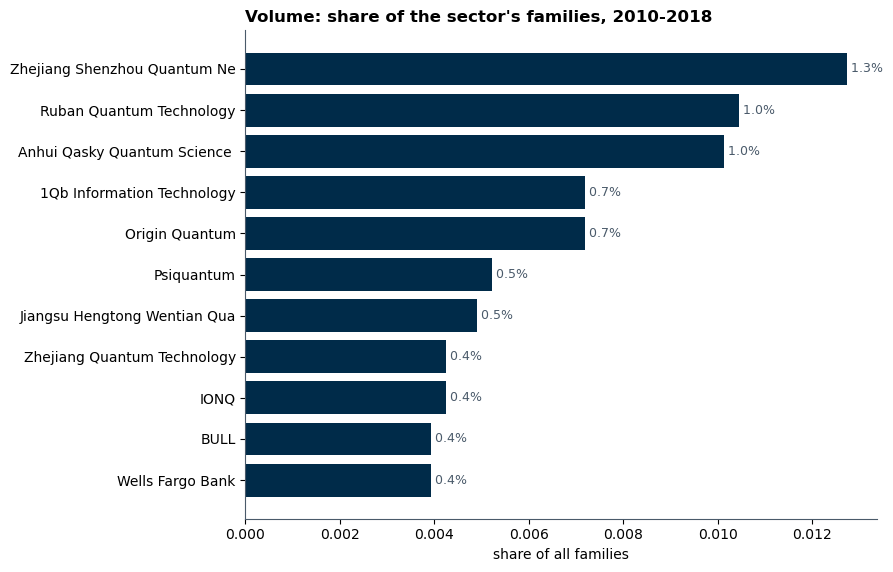

In [99]:
volume = (n_families / len(FAMILIES)).reindex(TOP).rename("volume")
firm_bars(volume, f"Volume: share of the sector's families, {WINDOW[0]}-{WINDOW[1]}", "share of all families", fmt="{:.1%}")

### 4.2 Refinement: shares over time, who gains and who loses?

A single average number for the whole period hides the dynamics. The same share, **year by year**, shows changes of power in the sector.

$$\text{Share}_{f,t}=\frac{\text{families of firm } f \text{ with priority year } t}{\text{all families of the sector with priority year } t}$$

We plot it over the whole period, smoothed with a 3-year moving average (one year is often a handful of families). The last two years are incomplete because applications are published 18 months after filing; a share suffers less than a count, but read them with care.

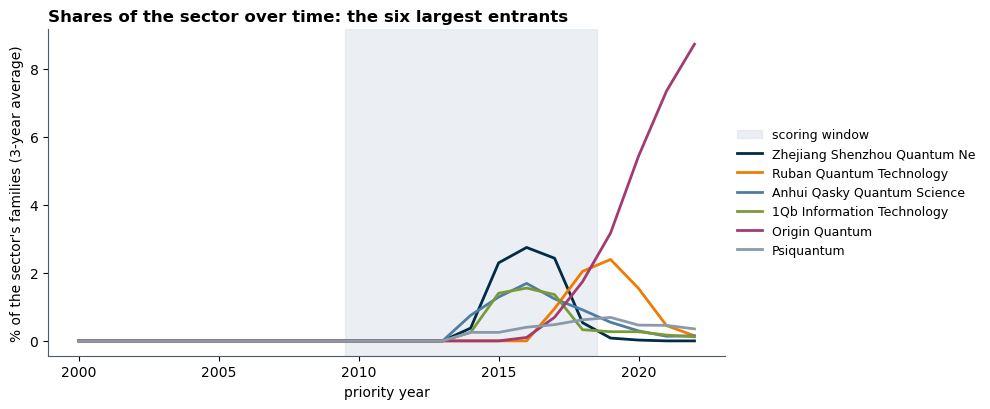

In [100]:
yearly = (clean_owners.merge(families_all[["docdb_family_id", "priority_year"]], on="docdb_family_id")
                     .groupby(["priority_year", "firm"]).docdb_family_id.nunique()
                     .unstack(fill_value=0))
total = families_all.groupby("priority_year").docdb_family_id.nunique()
share = yearly.reindex(columns=TOP, fill_value=0).div(total, axis=0)
smooth = share.rolling(3, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axvspan(WINDOW[0] - 0.5, WINDOW[1] + 0.5, color=LIGHT, alpha=0.5, label="scoring window")
for k, f in enumerate(TOP[:6]):
    ax.plot(smooth.index, smooth[f] * 100, color=LINES[k], lw=2, label=SHORT[f])
ax.set_xlabel("priority year")
ax.set_ylabel("% of the sector's families (3-year average)")
ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1.0, 0.5))
ax.set_title("Shares of the sector over time: the six largest entrants")
plt.tight_layout()
plt.show()

To turn the dynamics into a number, the **change of share** inside the window: the change of share is computed as the difference of the avwerage share in (2017-2018) minus the average share in (2015-2016), in percentage points. Positive means the firm is gaining weight and we are considering the last two years since we are dealing with entrant firms.

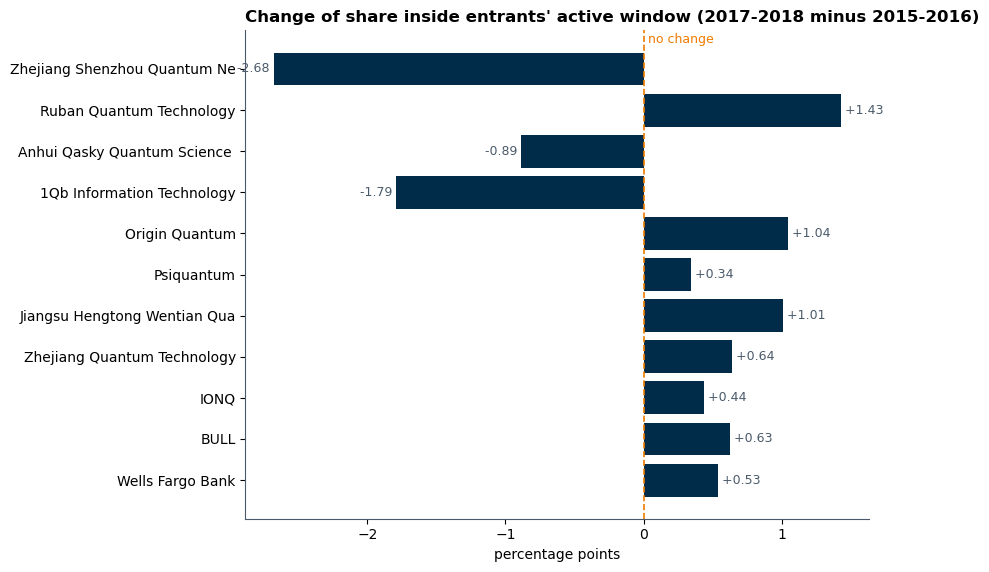

In [101]:
# check active period for entrants (2017-18 vs 2015-16) 
ACTIVE_MID = SPLIT_YEAR + (WINDOW[1] - SPLIT_YEAR) // 2   # 2016
in_active_window = share.loc[SPLIT_YEAR:WINDOW[1]]
volume_change = ((in_active_window.loc[ACTIVE_MID + 1:].mean() - in_active_window.loc[:ACTIVE_MID].mean()) * 100).rename("volume_change")

firm_bars(
    volume_change,
    f"Change of share inside entrants' active window ({ACTIVE_MID + 1}-{WINDOW[1]} minus {SPLIT_YEAR}-{ACTIVE_MID})",
    "percentage points",
    fmt="{:+.2f}",
    ref=0,
    ref_label="no change"
)

### 4.3 Refinement: Recent Momentum (Who is accelerating in the last 2 years of our window?)

A firm might have a large historical portfolio but low recent activity, or vice versa. To capture who is driving the current wave of Quantum Computing innovation, we measure **Recent Momentum**: the share of an enterprise's total portfolio filed in the most recent years of the window considered for the anlysis.

$$\text{Momentum}_{f}=\frac{\text{families of firm f}}{\text{total families of firm f in the window}}$$

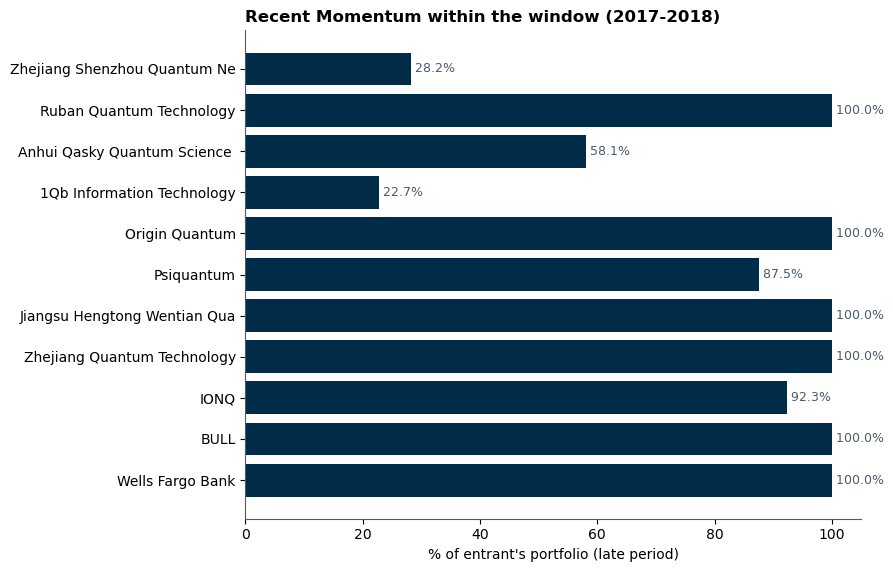

In [102]:
RECENT_WINDOW_START = 2017  # we consider as recent years, the last 2 years of our considered window 

firm_with_years = clean_owners.merge(families_all[["docdb_family_id", "priority_year"]], on="docdb_family_id")
firm_in_window = firm_with_years[firm_with_years.docdb_family_id.isin(FAMILIES)]

recent_vol = firm_in_window[firm_in_window.priority_year >= RECENT_WINDOW_START].groupby("firm").docdb_family_id.nunique()
total_vol = firm_in_window.groupby("firm").docdb_family_id.nunique()

recent_momentum = ((recent_vol / total_vol) * 100).reindex(TOP).fillna(0).rename("recent_momentum") 

firm_bars(
    recent_momentum, 
    f"Recent Momentum within the window ({RECENT_WINDOW_START}-{WINDOW[1]})", 
    "% of entrant's portfolio (late period)", 
    fmt="{:.1f}%"
)

**Reading volume results**

* **Small shares of the overall sector:** the selected entrants account individually for approximately **0.4%–1.3%** of all sector families in 2010–2018. Zhejiang Shenzhou Quantum Network Technology has the largest share (**1.3%**), followed by Ruban Quantum Technology and Anhui Qasky (both **1.0%**). 1Qb Information Technology and Origin Quantum each account for **0.7%**; the remaining firms are between **0.4%** and **0.5%**.
* **Different trajectories over time:** the six-firm time series shows activity emerging around 2014–2015, with peaks at different moments. Zhejiang Shenzhou reaches an early peak and then declines; Ruban rises later, peaking around 2019; Origin Quantum accelerates sharply at the end of the scoring window and beyond. The series extends beyond 2018 to show the subsequent trajectory, but the shaded area marks the 2010–2018 scoring window.
* **Change within the entrants' active window:** comparing average shares in 2017–2018 with 2015–2016, the largest gains are recorded by **Ruban (+1.43 percentage points)**, **Origin Quantum (+1.04 pp)** and **Jiangsu Hengtong Wentian (+1.01 pp)**. Zhejiang Shenzhou (**−2.68 pp**), 1Qb (**−1.79 pp**) and Anhui Qasky (**−0.89 pp**) lose relative share; the other firms show smaller positive changes.
* **Recent momentum:** the share of each firm's portfolio filed in 2017–2018 is **100%** for Ruban, Origin Quantum, Jiangsu Hengtong, Zhejiang Quantum Technology, BULL and Wells Fargo Bank. It is also high for PsiQuantum (**87.5%**) and IonQ (**92.3%**), while Zhejiang Shenzhou (**28.2%**), Anhui Qasky (**58.1%**) and 1Qb (**22.7%**) have a larger portion of their portfolio earlier in the window.

## 5. Influence: technological impact

### 5.1 Basics: forward citations within 5 years, compared with the same year

A family is influential if later inventions **build on it**, so we count its forward citations:

- **between families**: `TLS228_DOCDB_FAM_CITN` has one row per pair *citing family → cited family*, collecting the citations made by any publication of one family to any publication of the other;
- **within 5 years** of the first publication of the cited family, so that old and young families have the same time to be cited. The date of a citation is the first publication year of the **citing** family;
- we drop a family citing itself; citations from the same firm (self-citations) stay in, as in the OECD indicators.

First, the citations and their dates:

In [103]:
q = db.query(
    TLS228_DOCDB_FAM_CITN.docdb_family_id.label("citing_family"),
    TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.label("cited_family"),
).filter(TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.in_(FAMILIES))

fcit = patstat.df(q)
fcit = fcit[fcit.citing_family != fcit.cited_family]

q_cit = (
    db.query(TLS201_APPLN.docdb_family_id, func.min(TLS201_APPLN.earliest_publn_year).label("year"))
    .filter(TLS201_APPLN.docdb_family_id.in_([int(f) for f in fcit.citing_family.unique()]))
    .filter(TLS201_APPLN.earliest_publn_year < 9999)
    .group_by(TLS201_APPLN.docdb_family_id)
)

fcit["citing_year"] = fcit.citing_family.map(patstat.df(q_cit).set_index("docdb_family_id").year)
fcit["cited_year"] = fcit.cited_family.map(families.set_index("docdb_family_id").first_publn_year)
fcit["lag"] = fcit.citing_year - fcit.cited_year         # years between the two first publications

print(f"{len(fcit):,} citing-cited pairs, from {fcit.citing_family.nunique():,} citing families")

53,013 citing-cited pairs, from 20,706 citing families


A raw count is unfair across years: older families had more citing patents around them and more time in the data. So we divide each family's count by the **mean of the families with the same priority year** $t$.

What about the **field**? Citation habits differ a lot between fields, so in general the comparison should be made within the same field and year. Here all families belong to our defined **Quantum Computing sector**: the technological scope is fixed by our sector boundary, and comparing within the year **is** like comparing within field and year.

$$\text{fwd}^{norm}_{i}=\frac{\text{fwd}_{i}}{\bar F_{t}}\qquad\text{with}\qquad \bar F_{t}=\frac{1}{N_{t}}\sum_{j\,\in\,t}\text{fwd}_{j}$$

- $\text{fwd}_i$: citations received by family $i$ within 5 years; $t$ is its priority year;
- $N_{t}$: the number of families of the sector with priority year $t$.

A value of **1** means "cited as much as the average family of the sector filed in the same year"; 2 means twice as much.

We write it as a function of the window `w`, because the refinements use other windows. A window is counted only if the data cover it: PATSTAT Spring 2026 has the citations up to about 2025 (`LAST_YEAR`), so a family first published in 2022 has no complete 5-year window, and its value is set to *missing* rather than to a count that is too low.

In [104]:
LAST_YEAR = 2025                      # last year of citations covered by the PATSTAT edition
COHORT = ["priority_year"]            # comparing based on priority year within our sector


def forward_citations(w):
    """Citations received within w years of the first publication; missing if the window is not complete."""
    counts = fcit[fcit.lag.between(0, w)].groupby("cited_family").citing_family.nunique()
    fwd = families.docdb_family_id.map(counts).fillna(0)
    complete = families.first_publn_year + w <= LAST_YEAR
    return fwd.where(complete)


def normalise_by_cohort(values):
    """Each family's value divided by the mean of the families with the same priority year."""
    mean_cohort = values.groupby([families[c] for c in COHORT]).transform("mean")
    return (values / mean_cohort).where(mean_cohort > 0, 0.0).where(values.notna())


families["fwd5"] = forward_citations(5)
families["fwd5_norm"] = normalise_by_cohort(families.fwd5)
families.groupby("priority_year").fwd5.mean().round(2).to_frame("mean fwd5 (the denominator)").T

priority_year,2010,2011,2012,2013,2014,2015,2016,2017,2018
mean fwd5 (the denominator),6.83,11.99,10.64,16.1,16.04,18.92,17.41,12.33,10.11


Read the means by year: they move from year to year, and they fall in the last years because younger families are cited less or the data stop. The normalisation removes this, because each family is compared only with the families of its own year. The influence of a firm is the **average** of its families:

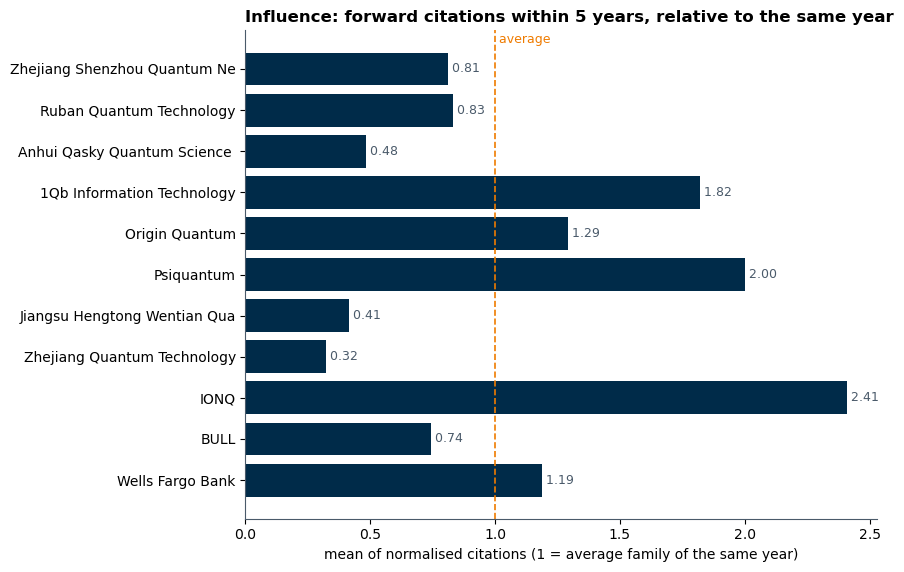

In [105]:
influence = per_firm("fwd5_norm").rename("influence")
firm_bars(influence, "Influence: forward citations within 5 years, relative to the same year",
          "mean of normalised citations (1 = average family of the same year)", ref=1, ref_label="average")

**Watch out.** An average is pulled up by one star family: a firm with 9 uncited families and one blockbuster can look influential. Refinement 5.4 looks at the top of the distribution instead.

### 5.2 Refinement: a shorter or a longer window (3 and 7 years)

A short window measures how fast a family is noticed; a long one is closer to its total impact, but the last priority years have no complete window yet, so it rests on the older families only. Does the window change the story?

In [106]:
for w in [3, 7]:
    families[f"fwd{w}_norm"] = normalise_by_cohort(forward_citations(w))

by_window = pd.concat([per_firm(f"fwd{w}_norm") for w in [3, 5, 7]], axis=1)
by_window.columns = ["3 years", "5 years", "7 years"]
by_window["complete 7y families"] = (
    fam_firm.merge(families[["docdb_family_id", "fwd7_norm"]], on="docdb_family_id")
    .groupby("firm")["fwd7_norm"].count().reindex(TOP)
)
print("Families with a complete window:",
      {w: f"{families[f'fwd{w}_norm'].notna().mean():.0%}" for w in [3, 5, 7]})
print("Rank correlation with the 5-year ranking:",
      by_window[["3 years", "5 years", "7 years"]].corr(method="spearman")["5 years"].drop("5 years").round(2).to_dict())
by_window.rename(index=SHORT).round(2)

Families with a complete window: {3: '99%', 5: '98%', 7: '66%'}
Rank correlation with the 5-year ranking: {'3 years': 0.95, '7 years': 0.28}


,3 years,5 years,7 years,complete 7y families
firm,,,,
Zhejiang Shenzhou Quantum Ne,0.93,0.81,0.83,38
Ruban Quantum Technology,0.84,0.83,1.50,20
Anhui Qasky Quantum Science,0.50,0.48,0.49,27
1Qb Information Technology,1.61,1.82,1.84,27
Origin Quantum,1.29,1.29,1.72,9
Psiquantum,1.57,2.00,0.58,2
Jiangsu Hengtong Wentian Qua,0.45,0.41,0.46,14
Zhejiang Quantum Technology,0.28,0.32,0.58,8
IONQ,2.42,2.41,0.54,1


* The **3-year and 5-year rankings are closely aligned** (Spearman correlation **0.95**), while the 7-year ranking is less stable relative to the 5-year ranking (**0.28**). The 5-year measure has a complete observation window for **98%** of sector families; coverage falls to **66%** for the 7-year measure.
* **IonQ** has the highest 5-year influence score (**2.41**), followed by **PsiQuantum (2.00)** and **1Qb Information Technology (1.82)**. These values indicate citation levels above the average family in the same priority-year cohort. Origin Quantum is also above the benchmark (**1.29**), while Wells Fargo Bank is modestly above it (**1.19**).
* The 7-year values for the youngest portfolios are based on very few eligible families and should not be compared uncritically with the 5-year scores. IonQ's 7-year value (**0.54**) is based on **1** family; PsiQuantum's (**0.58**) on **2**; and BULL's (**1.71**) on **1**. Wells Fargo Bank has no complete 7-year family, so its value is missing.
* Some firms have a broader eligible base: Zhejiang Shenzhou has **38** complete 7-year families, Anhui Qasky **27**, 1Qb **27**, Ruban **20** and Jiangsu Hengtong **14**. Their longer-window values are consequently more informative than those based on one or two families.

For the main influence comparison, the **5-year normalised score** remains the most balanced choice: it retains almost complete coverage while allowing a meaningful citation window.

If the order of the firms is the same in the three columns, the choice of the window does not matter much. A firm that climbs with the longer window has patents noticed late but used for long.

### 5.3 Refinement: who cites the firm, competitors or examiners?

A citation can be added by the **applicant** of the citing patent (origin `APP` in `TLS212`) or by the **examiner** during the search or examination (`SEA`, `ISR`, `SUP`, `EXA`...). The difference matters:

- an **applicant** citation means that a competitor *knew* the patent when it filed: a real knowledge flow, and visibility in the market;
- an **examiner** citation means that the patent is relevant prior art, which the citing applicant may never have read.

The origin is recorded at the level of **publications**, so we go from our global families to their publications (`TLS211`), then to the publications that cite them. We keep only citing **EP** publications: at the USPTO applicants must disclose all the prior art they know, so US applicant citations would mix different legal practices.

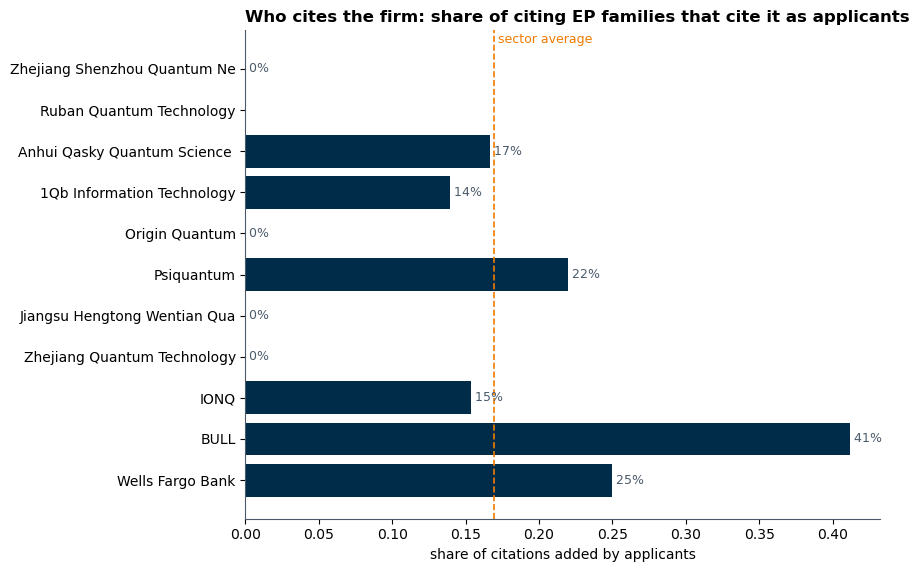

In [107]:
CITING_OFFICES = ["EP"]

# 1. All the publications of the families of the window (any office)
q = (db.query(TLS211_PAT_PUBLN.pat_publn_id, TLS201_APPLN.docdb_family_id.label("cited_family"))
     .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
     .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES)))
pubs = patstat.df(q)

# 2. The citations they receive, with their origin
q = (
    db.query(TLS212_CITATION.pat_publn_id.label("citing_publn"), TLS212_CITATION.citn_replenished,
             TLS212_CITATION.citn_id, TLS212_CITATION.citn_origin, TLS212_CITATION.cited_pat_publn_id)
    .filter(TLS212_CITATION.cited_pat_publn_id.in_([int(p) for p in pubs.pat_publn_id]))
)
cit = patstat.df(q)
cit["cited_family"] = cit.cited_pat_publn_id.map(pubs.set_index("pat_publn_id").cited_family)

# 3. The office and the family of each citing publication
q = (
    db.query(TLS211_PAT_PUBLN.pat_publn_id.label("citing_publn"), TLS211_PAT_PUBLN.publn_auth.label("citing_office"),
             TLS201_APPLN.docdb_family_id.label("citing_family"))
    .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS211_PAT_PUBLN.pat_publn_id.in_([int(p) for p in cit.citing_publn.unique()]))
)
cit = cit.merge(patstat.df(q), on="citing_publn")
cit = cit[cit.citing_family != cit.cited_family]
cit["who"] = np.where(cit.citn_origin.str.strip() == "APP", "applicant", "examiner or other")

ep_cit = (cit[cit.citing_office.isin(CITING_OFFICES)]
          .drop_duplicates(["citing_family", "cited_family", "who"])
          .merge(fam_firm, left_on="cited_family", right_on="docdb_family_id"))
applicant_share = (ep_cit.who == "applicant").groupby(ep_cit.firm).mean().reindex(TOP).rename("applicant_share")
firm_bars(applicant_share, "Who cites the firm: share of citing EP families that cite it as applicants",
          "share of citations added by applicants", fmt="{:.0%}",
          ref=(ep_cit.who == "applicant").mean(), ref_label="sector average")

In [108]:
ep_cit.groupby("firm")["citing_family"].nunique().reindex(TOP).fillna(0).astype(int).rename("citing_EP_families").to_frame()

,citing_EP_families
firm,
ZHEJIANG SHENZHOU QUANTUM NETWORK TECHNOLOGY,6
RUBAN QUANTUM TECHNOLOGY,0
ANHUI QASKY QUANTUM SCIENCE TECHNOLOGY,6
1QB INFORMATION TECHNOLOGY,52
ORIGIN QUANTUM,12
PSIQUANTUM,24
JIANGSU HENGTONG WENTIAN QUANTUM INFORMATION RESEARCH INSTITUTE,1
ZHEJIANG QUANTUM TECHNOLOGY,1
IONQ,33


A firm with a high applicant share is **watched by its competitors**: its patents are known reference points (read it with the number of citations).

* **PsiQuantum** has the highest share among the quantum specialists (**22%**, across **24** citing EP families). **IonQ** records **15%** across **33** families and **1Qb Information Technology** **14%** across **52** families; all are close to the sector reference of approximately **17%**.
* **BULL** records **41%**, but this is based on only **16** citing EP families. **Wells Fargo Bank** records **25%** across **6** families, while **Anhui Qasky** is at **17%** across **6** families. These percentages should be interpreted with the smaller bases in mind.
* Zhejiang Shenzhou, Origin Quantum, Jiangsu Hengtong and Zhejiang Quantum Technology have **0%** applicant-added citations in this EP sample (with 6, 12, 1 and 1 citing families respectively). Ruban has no citing EP families in the table, so its share is not meaningfully informative.

The result points to the strongest direct applicant-citation visibility for PsiQuantum, IonQ and 1Qb, while the low or zero shares for several firms may also reflect the limited European citation footprint of their portfolios.

### 5.4 Refinement: blocking patents, X and I citations at the top of the sector

Not all citations are equal. In a search report the examiner gives each cited document a **category** (`TLS215_CITN_CATEG`):

| Category | Meaning for the citing application |
|---|---|
| **X** | the cited document **alone** destroys the novelty or the inventive step of the claim |
| **I** | the cited document **alone** destroys the inventive step of the claim (EPO, since 2012) |
| Y | relevant only in combination with another document |
| A | general background |

A family often cited as **X or I** stood in the way of later applications: competitors had to narrow their claims or give up. It is a **blocking patent**, the strongest form of influence. `CITN_CATEG` can hold several letters (e.g. `XI`), so we look for an X or an I anywhere in it.

For each family we count the distinct families that cite it as X or I, and we call **blocking** the families in the **top 10% of their priority year**, with at least one such citation. As in 5.1, comparing inside the year is fair to young families, and the field is fixed by our global sector boundary.

Each family is then **blocking (1) or not (0)**. For a firm we compute two numbers from these 0/1 values:

$$\text{Blocking share}_f=\frac{\text{blocking families of } f}{\text{families of } f}\qquad\qquad \text{Share of the sector's blocking}_f=\frac{\text{blocking families of } f}{\text{all blocking families of the sector}}$$

The first is the average of the 0/1 values over the firm's families: the share of its portfolio that blocks others.

In [109]:
TOP_SHARE = 0.10              # top 10% of each priority year

q = (
    db.query(TLS215_CITN_CATEG.pat_publn_id.label("citing_publn"), TLS215_CITN_CATEG.citn_replenished,
             TLS215_CITN_CATEG.citn_id, TLS215_CITN_CATEG.citn_categ)
    .filter(TLS215_CITN_CATEG.pat_publn_id.in_([int(p) for p in cit.citing_publn.unique()]))
)
categ = patstat.df(q)
xi_keys = categ[categ.citn_categ.str.contains("X|I", regex=True)][["citing_publn", "citn_replenished", "citn_id"]]
xi = cit.merge(xi_keys.drop_duplicates(), on=["citing_publn", "citn_replenished", "citn_id"])

families["xi"] = families.docdb_family_id.map(xi.groupby("cited_family").citing_family.nunique()).fillna(0)
threshold = families.groupby(COHORT).xi.transform(lambda s: s.quantile(1 - TOP_SHARE))   # cut-off of each year
families["blocking"] = ((families.xi > threshold) & (families.xi > 0)).astype(int)

owners_of = fam_firm.groupby("docdb_family_id").firm.agg(", ".join)     # co-owned families: all owners
print(f"Blocking families: {families.blocking.sum():,} of {len(families):,}. The ten strongest:")
(families.assign(owners=families.docdb_family_id.map(owners_of).fillna("(not a company)"))
         .sort_values("xi", ascending=False)[["docdb_family_id", "priority_year", "xi", "owners"]].head(10))

Blocking families: 239 of 3,061. The ten strongest:


,docdb_family_id,priority_year,xi,owners
1292,54554938,2014,20.0,RIGETTI
2091,60935992,2017,11.0,GOOGLE
918,47992613,2011,9.0,LOS ALAMOS NATIONAL SECURITY
1722,58662742,2015,9.0,(not a company)
3419,67301223,2018,9.0,BIOVENTURES
2267,62075687,2016,8.0,HUAWEI
3848,68766205,2018,8.0,ATOM COMPUTING
1195,52997221,2015,8.0,HITACHI
1111,52007585,2013,8.0,"QUANTUM COMMUNICATION TECHNOLOGY, QUANTUM..."
2272,62091366,2015,8.0,RIGETTI


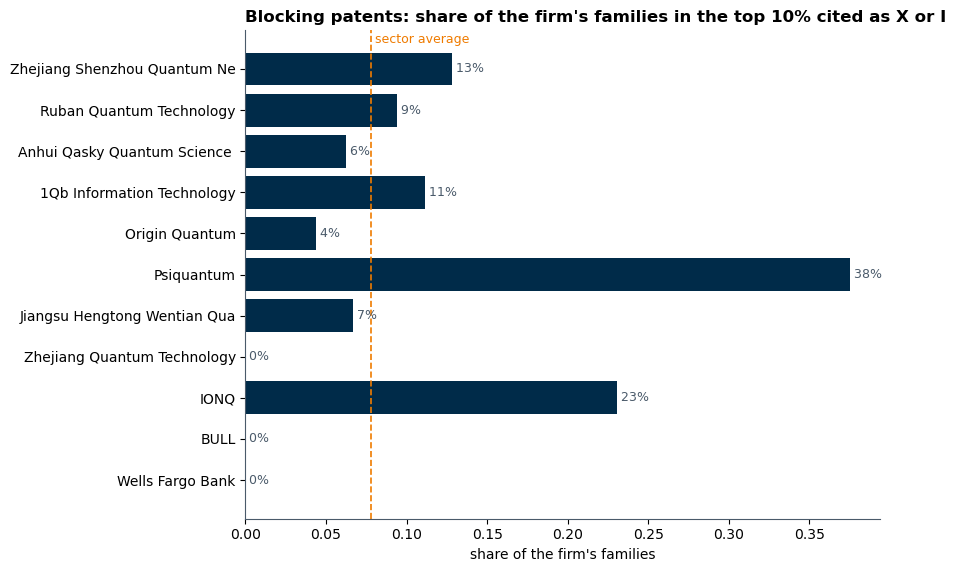

,blocking families,blocking_share,share_of_sector_blocking
firm,,,
Zhejiang Shenzhou Quantum Ne,5,0.13,0.02
Ruban Quantum Technology,3,0.09,0.01
Anhui Qasky Quantum Science,2,0.06,0.01
1Qb Information Technology,4,0.11,0.02
Origin Quantum,1,0.04,0.00
Psiquantum,6,0.38,0.03
Jiangsu Hengtong Wentian Qua,1,0.07,0.00
Zhejiang Quantum Technology,0,0.00,0.00
IONQ,3,0.23,0.01


In [110]:
blocking_share = per_firm("blocking").rename("blocking_share")                 # mean of 0/1 = share of families
blocking_power = (per_firm("blocking", "sum") / families.blocking.sum()).rename("share_of_sector_blocking")

firm_bars(blocking_share, f"Blocking patents: share of the firm's families in the top {TOP_SHARE:.0%} cited as X or I",
          "share of the firm's families", fmt="{:.0%}", ref=families.blocking.mean(), ref_label="sector average")
pd.concat([per_firm("blocking", "sum").rename("blocking families"), blocking_share, blocking_power],
          axis=1).rename(index=SHORT).round(2)

`blocking_share` is the **quality** of the portfolio (how many of its families block others), `share_of_sector_blocking` is the **power** in the sector (how many of the sector's blocking patents the firm owns).

* **PsiQuantum** stands out: **38%** of its families (**6**) are blocking, well above the sector reference (239 blocking families out of 3,061, approximately **8%**). **IonQ** follows at **23%** (**3** families).
* **Zhejiang Shenzhou** records **13%** (**5** families), and **1Qb Information Technology** **11%** (**4**). Ruban is at **9%** (**3**), while Jiangsu Hengtong (**7%**, 1 family) is close to the sector reference.
* Anhui Qasky (**6%**, 2 families) and Origin Quantum (**4%**, 1 family) are below the reference. Zhejiang Quantum Technology, BULL and Wells Fargo Bank have no families classified as blocking.
* Despite the high within-portfolio shares for some firms, no entrant accounts for more than **3%** of the sector's blocking families; PsiQuantum has the largest sector contribution.

The distinction matters: a small portfolio can have a high blocking share without owning a large fraction of all blocking patents in the sector.

### 5.5 Refinement: backward citations and citations to science

While forward citations measure future impact, **backward citations** and **non-patent literature (NPL) citations** measure the foundations of the invention:

- **Backward citations:** The number of earlier patent documents cited by the invention (excluding NPL, self-citations included). A high count indicates that the patent underwent rigorous screening against an extensive prior art landscape, reflecting technological solidity.
- **Citations to science (NPL):** Links to scientific papers and non-patent literature (`cited_npl_publn_id > 0`). In fields like Quantum Computing, inventions tightly coupled with academic and scientific literature tend to be more radical and of higher technological quality.

As with forward citations, we normalise these metrics by priority year cohort to account for generational differences in citation intensity.

npl_type
a    33838
s     5652
w     1002
b      257
e        3
d        1
Name: count, dtype: int64


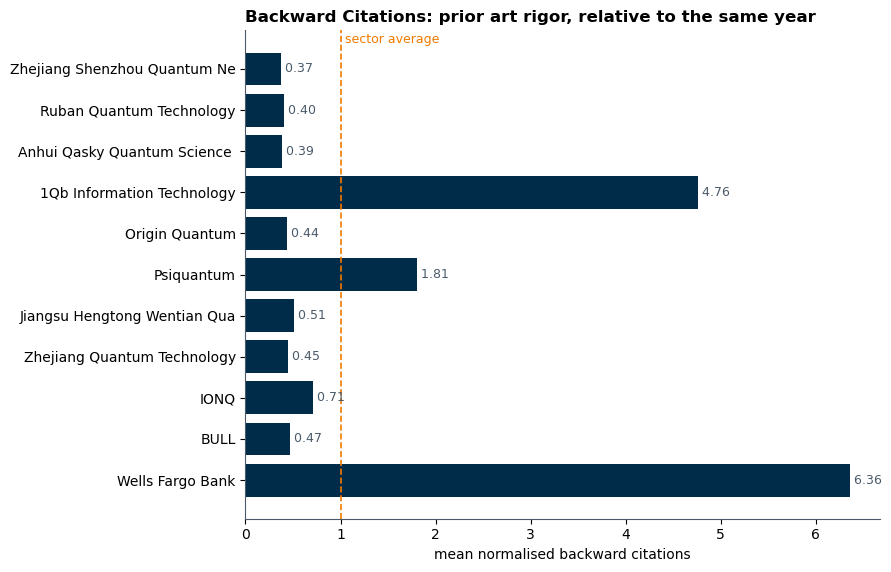

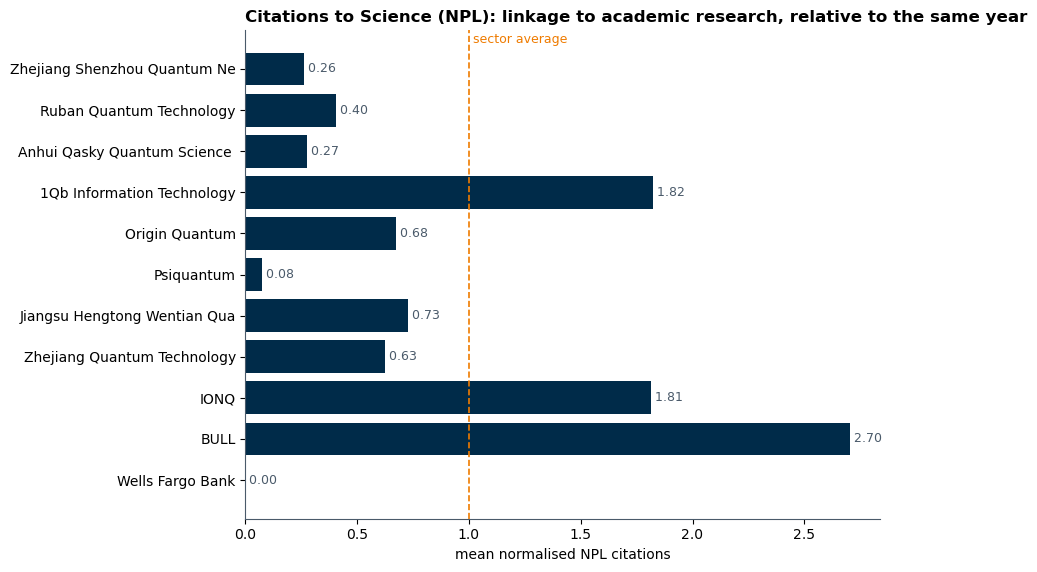

,backward_citations,science_citations
firm,,
Zhejiang Shenzhou Quantum Ne,0.37,0.26
Ruban Quantum Technology,0.40,0.40
Anhui Qasky Quantum Science,0.39,0.27
1Qb Information Technology,4.76,1.82
Origin Quantum,0.44,0.68
Psiquantum,1.81,0.08
Jiangsu Hengtong Wentian Qua,0.51,0.73
Zhejiang Quantum Technology,0.45,0.63
IONQ,0.71,1.81


In [111]:
# Backward Patent Citations per family (excluding NPL)
q_back = (
    db.query(
        TLS201_APPLN.docdb_family_id.label("citing_family"),
        TLS212_CITATION.pat_publn_id,
        TLS212_CITATION.cited_pat_publn_id,
        TLS212_CITATION.cited_npl_publn_id
    )
    .join(TLS211_PAT_PUBLN, TLS211_PAT_PUBLN.pat_publn_id == TLS212_CITATION.pat_publn_id)
    .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
)
back_df = patstat.df(q_back)

back_df["cited_pat_publn_id"] = pd.to_numeric(back_df["cited_pat_publn_id"], errors="coerce").fillna(0)
back_df["cited_npl_publn_id"] = pd.to_numeric(back_df["cited_npl_publn_id"], errors="coerce").fillna(0)

back_pat = back_df[back_df.cited_pat_publn_id > 0].groupby("citing_family").cited_pat_publn_id.nunique()
families["back_citations"] = families.docdb_family_id.map(back_pat).fillna(0)

# Citations to science (NPL) per family 
q_npl = (
    db.query(TLS201_APPLN.docdb_family_id.label("citing_family"),
             TLS214_NPL_PUBLN.npl_publn_id, TLS214_NPL_PUBLN.npl_type)
    .select_from(TLS201_APPLN)
    .join(TLS211_PAT_PUBLN, TLS211_PAT_PUBLN.appln_id == TLS201_APPLN.appln_id)
    .join(TLS212_CITATION, TLS212_CITATION.pat_publn_id == TLS211_PAT_PUBLN.pat_publn_id)
    .join(TLS214_NPL_PUBLN, TLS214_NPL_PUBLN.npl_publn_id == TLS212_CITATION.cited_npl_publn_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
    .filter(TLS212_CITATION.cited_npl_publn_id != "0")  
    .distinct()
)
npl = patstat.df(q_npl)
npl = npl[~npl.npl_publn_id.astype(str).str.strip().isin(["", "0"])]
print(npl.npl_type.value_counts())          # check which type are the journal articles
# scientific = articles only ("s" in the tutorial); not all NPL is science
sci = npl[npl.npl_type == "s"]
families["sci_citations"] = families.docdb_family_id.map(sci.groupby("citing_family").npl_publn_id.nunique()).fillna(0)


families["back_norm"] = normalise_by_cohort(families.back_citations)
families["sci_norm"] = normalise_by_cohort(families.sci_citations)

back_firm = per_firm("back_norm").rename("backward_citations")
sci_firm = per_firm("sci_norm").rename("science_citations")

firm_bars(back_firm, "Backward Citations: prior art rigor, relative to the same year", 
          "mean normalised backward citations", ref=1, ref_label="sector average")

firm_bars(sci_firm, "Citations to Science (NPL): linkage to academic research, relative to the same year", 
          "mean normalised NPL citations", ref=1, ref_label="sector average")

pd.concat([back_firm, sci_firm], axis=1).rename(index=SHORT).round(2)

* The table shows substantial differences in the prior-art and scientific foundations of the firms' patents. **Wells Fargo Bank** has the highest mean number of backward citations (**6.36**), followed by **1Qb Information Technology (4.76)**. Among the quantum-focused firms, **PsiQuantum** records **1.81** backward citations per family, while most other entrants are below 1.
* For citations to scientific literature, **BULL** has the highest value (**2.70**); **1Qb Information Technology** (**1.82**) and **IonQ** (**1.81**) are also comparatively high. Origin Quantum (**0.68**), Jiangsu Hengtong (**0.73**) and Zhejiang Quantum Technology (**0.63**) show intermediate values, while the other Chinese entrants range from **0.26** to **0.40**.
* **PsiQuantum** combines a relatively high backward-citation value (**1.81**) with a low science-citation value (**0.08**). **Wells Fargo Bank** shows the opposite contrast in the table: **6.36** backward citations and **0.00** science citations.
* These are descriptive averages, not standalone quality rankings. Citation practices and the availability of citation metadata can differ across patent offices, so differences between firms should be interpreted in light of their filing geographies and portfolio composition.

### 5.6 Refinement: Originality and Generality

To understand the structural nature of a firm's technology portfolio, we compute two classic indexes based on CPC/IPC technological classes (using the Herfindahl-Hirschman dispersion index $1 - \sum s_{ik}^2$):

- **Originality:** Measures how widely recombinant an invention is. A high originality score means the patent builds upon prior art drawn from many different, distant technological fields.
- **Generality:** Measures how widely a patent is applied later. A high generality score means the patent is cited by subsequent inventions spanning a broad range of diverse technological fields, acting much like a General-Purpose Technology (GPT).

Both metrics are aggregated at the firm level to evaluate the breadth of their R&D output.

Families with a value: {'originality': 0.65, 'generality': 0.64}


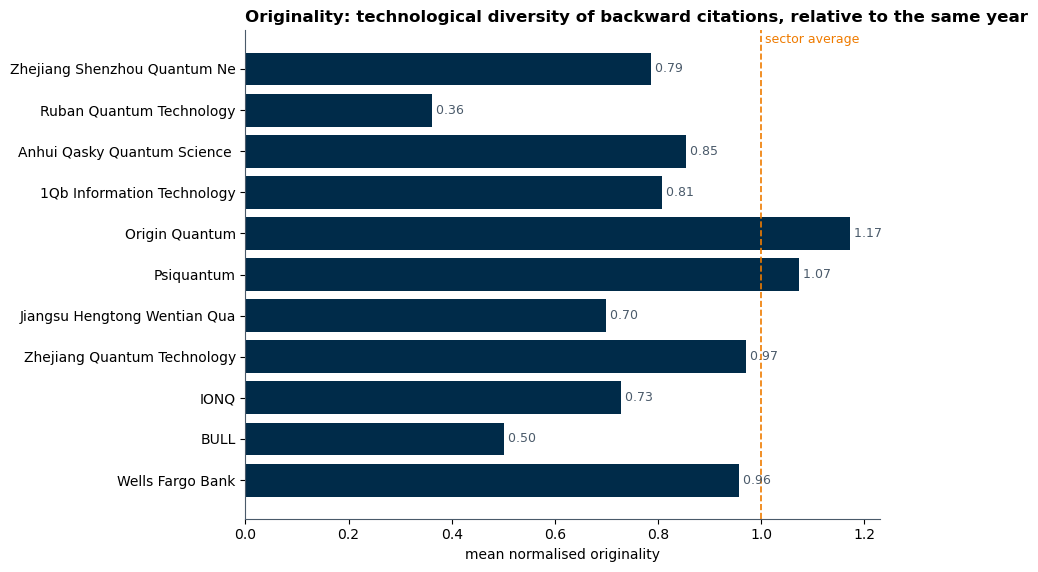

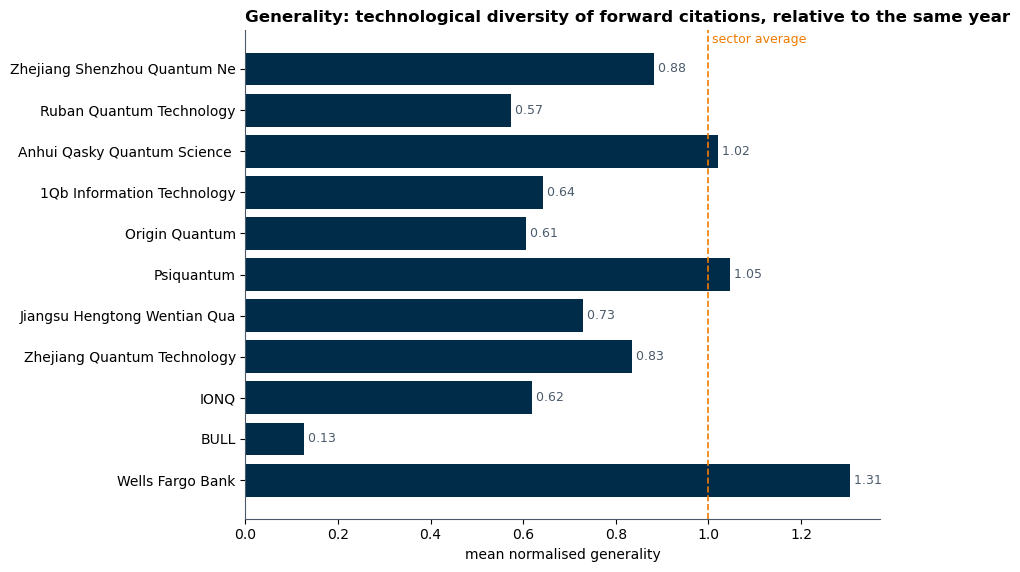

,originality,generality
firm,,
Zhejiang Shenzhou Quantum Ne,0.79,0.88
Ruban Quantum Technology,0.36,0.57
Anhui Qasky Quantum Science,0.85,1.02
1Qb Information Technology,0.81,0.64
Origin Quantum,1.17,0.61
Psiquantum,1.07,1.05
Jiangsu Hengtong Wentian Qua,0.70,0.73
Zhejiang Quantum Technology,0.97,0.83
IONQ,0.73,0.62


,n families with originality,n families with generality,families in the window
firm,,,
Zhejiang Shenzhou Quantum Ne,24,34,39
Ruban Quantum Technology,24,25,32
Anhui Qasky Quantum Science,15,20,31
1Qb Information Technology,31,35,22
Origin Quantum,13,19,22
Psiquantum,13,13,16
Jiangsu Hengtong Wentian Qua,10,6,15
Zhejiang Quantum Technology,8,4,13
IONQ,9,11,13


In [112]:
def family_fields(family_ids):
    """WIPO field shares of each DOCDB family (weights summed over its applications)."""
    ids, out = [int(i) for i in family_ids], []
    for s in range(0, len(ids), 5000):
        q = (db.query(TLS201_APPLN.docdb_family_id, TLS230_APPLN_TECHN_FIELD.techn_field_nr,
                      func.sum(TLS230_APPLN_TECHN_FIELD.weight).label("w"))
             .join(TLS230_APPLN_TECHN_FIELD, TLS230_APPLN_TECHN_FIELD.appln_id == TLS201_APPLN.appln_id)
             .filter(TLS201_APPLN.docdb_family_id.in_(ids[s:s + 5000]))
             .group_by(TLS201_APPLN.docdb_family_id, TLS230_APPLN_TECHN_FIELD.techn_field_nr))
        out.append(patstat.df(q))
    f = pd.concat(out)
    f["w"] = f.w.astype(float)
    f["w"] = f.w / f.groupby("docdb_family_id").w.transform("sum")
    return f


def dispersion(pairs, key, other, fields, min_n=5):
    """1 - sum of squared field shares over the `other` families linked to `key`.
    Hall-Jaffe correction n/(n-1); NaN below min_n links (the index is unstable)."""
    t = pairs.merge(fields.rename(columns={"docdb_family_id": other}), on=other)
    w = t.groupby([key, "techn_field_nr"]).w.sum().reset_index()
    w["s"] = w.w / w.groupby(key).w.transform("sum")
    d = 1 - (w.s ** 2).groupby(w[key]).sum()
    n = pairs.groupby(key)[other].nunique().reindex(d.index)
    return (d * n / (n - 1)).where(n >= min_n)

# 1. ORIGINALITY (Based on Backward Citations) Map cited publications -> families
cited_pubs = back_df.loc[back_df.cited_pat_publn_id > 0, "cited_pat_publn_id"].astype("int64").unique()
maps = []
for s in range(0, len(cited_pubs), 5000):
    q = (db.query(TLS211_PAT_PUBLN.pat_publn_id.label("cited_pat_publn_id"),
                  TLS201_APPLN.docdb_family_id.label("cited_family"))
         .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
         .filter(TLS211_PAT_PUBLN.pat_publn_id.in_([int(p) for p in cited_pubs[s:s + 5000]])))
    maps.append(patstat.df(q))
pub2fam = pd.concat(maps).drop_duplicates("cited_pat_publn_id")

b = back_df[back_df.cited_pat_publn_id > 0].copy()
b["cited_pat_publn_id"] = b.cited_pat_publn_id.astype("int64")
back_pairs = (b.merge(pub2fam, on="cited_pat_publn_id")[["citing_family", "cited_family"]]
                .drop_duplicates().query("citing_family != cited_family"))


# 2. GENERALITY (Based on Forward Citations) citing families within 5 years (same window as influence)
fwd_pairs = fcit[fcit.lag.between(0, 5)][["citing_family", "cited_family"]].drop_duplicates()

fields = family_fields(set(back_pairs.cited_family) | set(fwd_pairs.citing_family))

families["originality"] = families.docdb_family_id.map(dispersion(back_pairs, "citing_family", "cited_family", fields))
families["generality"] = families.docdb_family_id.map(dispersion(fwd_pairs, "cited_family", "citing_family", fields))
families["orig_norm"] = normalise_by_cohort(families.originality)
families["gen_norm"] = normalise_by_cohort(families.generality)
print("Families with a value:", families[["originality", "generality"]].notna().mean().round(2).to_dict())

orig_firm = per_firm("orig_norm").rename("originality")
gen_firm = per_firm("gen_norm").rename("generality")

firm_bars(
    orig_firm, 
    "Originality: technological diversity of backward citations, relative to the same year", 
    "mean normalised originality", 
    ref=1, 
    ref_label="sector average"
)

firm_bars(
    gen_firm, 
    "Generality: technological diversity of forward citations, relative to the same year", 
    "mean normalised generality", 
    ref=1, 
    ref_label="sector average"
)

orig_firm.rename(index=SHORT).round(2)
gen_firm.rename(index=SHORT).round(2)
display(pd.concat([orig_firm, gen_firm], axis=1).rename(index=SHORT).round(2))

n_used = (fam_firm.merge(families[["docdb_family_id", "orig_norm", "gen_norm"]], on="docdb_family_id")
                  .groupby("firm")[["orig_norm", "gen_norm"]].count()
                  .reindex(TOP)
                  .rename(columns={"orig_norm": "n families with originality",
                                   "gen_norm": "n families with generality"}))
n_used["families in the window"] = n_families.reindex(TOP)

n_used.rename(index=SHORT)

* Across the sector, **65%** of families have a valid originality value and **64%** a valid generality value. The firm-level means are normalised by priority-year cohort, so **1** is the reference level for the sector families of the same year.
* **Wells Fargo Bank** has the highest generality score (**1.31**), while **PsiQuantum** is the only quantum-focused entrant above 1 on both dimensions (**1.07** originality; **1.05** generality). **Origin Quantum** leads on originality (**1.17**) but has below-reference generality (**0.61**).
* **Anhui Qasky** is above the reference in generality (**1.02**) but below it in originality (**0.85**). Zhejiang Shenzhou is relatively high in generality (**0.88**) compared with originality (**0.79**), while 1Qb (**0.81**; **0.64**), IonQ (**0.73**; **0.62**) and Jiangsu Hengtong (**0.70**; **0.73**) are below 1 on both.
* Ruban records the lowest values (**0.36** originality; **0.57** generality). BULL is also low on both (**0.50**; **0.13**).
* Coverage varies by firm. For example, Zhejiang Shenzhou has values for **24** families on originality and **34** on generality; 1Qb has **31** and **35**; PsiQuantum has **13** on both. Zhejiang Quantum Technology has only **4** families with a generality value, so its generality estimate is based on a particularly small subset.

The two indices capture different things: originality concerns the technological diversity of the prior art used, while generality concerns the technological diversity of later citing inventions.

## 6. Success: quality as judged by the examiners

Success asks: **when the firm applies for a patent, do the examiners accept it?** A granted patent has passed an examination of novelty and inventive step, so a high grant rate signals inventions of good quality and well-drafted applications. 

### 6.1 Basics: share of global applications granted

Because many firms in our global dataset do not restrict their filings to the EPO, measuring success exclusively through European applications would create a bias. Instead, we compute the success rate across all national and regional patent offices where the firm files:

$$\text{Success}_f=\frac{\text{granted global applications of firm } f}{\text{global applications of firm } f}$$

`granted` is `Y` when PATSTAT has an indication of a grant, `N` otherwise. `N` therefore mixes refused, withdrawn and still pending applications; with the window ending in 2018 most applications have been decided. 
To focus purely on active substantive examinations, we exclude:
- **`WO`**: a PCT application is a request, not protection in a country;
- **`T`** (`appln_kind` in `TLS201`): translations of granted EP patents recorded as national applications in certain countries (Spain, Portugal, Poland, Denmark, Austria, etc.), which are always "granted" by default and counting it would inflate both success and globalization.

In [113]:
q = (
    db.query(
        TLS201_APPLN.appln_id, 
        TLS201_APPLN.docdb_family_id, 
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_kind, 
        TLS201_APPLN.granted
    )
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
)
members = patstat.df(q).drop_duplicates("appln_id")

# national applications: exclude PCT requests (WO) and translations of EP patents (kind T)
national = members[(members.appln_auth != "WO") & (members.appln_kind != "T")]

office_rate = national.groupby("appln_auth").agg(
    applications=("appln_id", "size"),
    granted=("granted", lambda s: (s == "Y").mean())
)
display(office_rate[office_rate.applications >= 20].sort_values("granted", ascending=False).round(2).T)

appln_auth,ES,RU,FR,AU,US,JP,TW,KR,CN,EP,CA,GB,IL,DE,SG
applications,64.0,24.0,26.00,242.00,2366.00,595.00,50.00,354.0,1677.00,709.00,260.00,147.00,20.0,80.00,45.0
granted,1.0,1.0,0.96,0.88,0.87,0.87,0.84,0.8,0.73,0.68,0.65,0.63,0.4,0.36,0.0


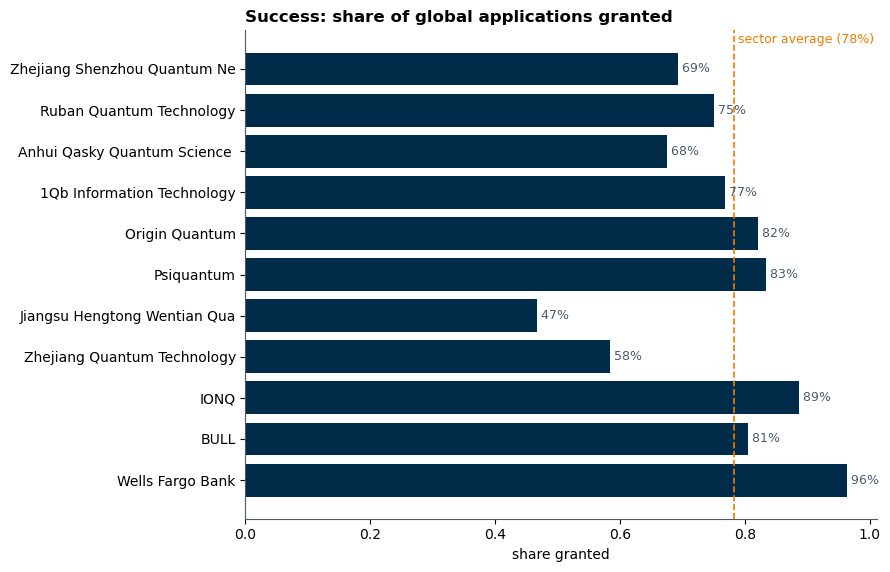

In [114]:
global_apps = national.merge(fam_firm, on="docdb_family_id")

success_global = global_apps.groupby("firm").granted.apply(lambda s: (s == "Y").mean()).reindex(TOP).rename("success_global")
sector_rate_global = (national.granted == "Y").mean()

firm_bars(
    success_global, 
    "Success: share of global applications granted", 
    "share granted", 
    fmt="{:.0%}",
    ref=sector_rate_global, 
    ref_label=f"sector average ({sector_rate_global:.0%})"
)

* The overall grant rate across the selected firms is approximately **78%**. **Wells Fargo Bank** records the highest firm-level rate (**96%**), followed by **IonQ (89%)**, **PsiQuantum (83%)**, **Origin Quantum (82%)** and **BULL (81%)**.
* **1Qb Information Technology** is close to the reference at **77%**, while Ruban records **75%**. Zhejiang Shenzhou (**69%**), Anhui Qasky (**68%**), Zhejiang Quantum Technology (**58%**) and Jiangsu Hengtong (**47%**) are below the sector average.
* Grant rates also vary substantially by office. In the displayed office table, the rates are **87%** for both the US and Japan, **73%** for China, **68%** for the EPO and **65%** for Canada. Germany (**36%**) and Singapore (**0%**) are lower in this sample; the number of applications differs considerably across offices.
* The firm-level results should therefore be read together with filing geography: a firm's grant rate reflects both the quality and maturity of its applications and the offices in which it chooses to file.

### 6.2 Refinement: success across offices, invention by invention

Offices apply different **patentability rules and standards**: the same invention can be granted in one country and refused in another. An invention granted at the EPO, in the USA, in China and in Japan has passed four different examinations: a strong signal. So we change the unit, from applications to **inventions**:

1. for each family, the share of its national applications that are granted
2. for each firm, the average over its families

As established in section 6.1, two kinds of family members  (**`WO`** and **Applications of kind `T`**) are **not** independent national examinations, so we exclude them.

To understand how grant standards differ across patent offices, we examine the grant rate by office for our sector's families:

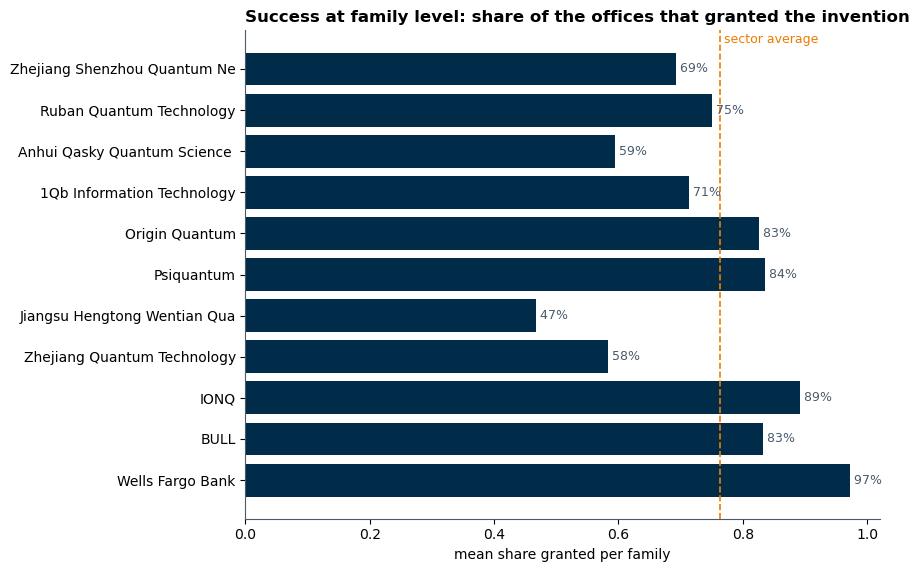

,6.1 global apps,6.2 family-level
firm,,
Zhejiang Shenzhou Quantum Ne,0.69,0.69
Ruban Quantum Technology,0.75,0.75
Anhui Qasky Quantum Science,0.68,0.59
1Qb Information Technology,0.77,0.71
Origin Quantum,0.82,0.83
Psiquantum,0.83,0.84
Jiangsu Hengtong Wentian Qua,0.47,0.47
Zhejiang Quantum Technology,0.58,0.58
IONQ,0.89,0.89


In [115]:
families["family_success"] = families.docdb_family_id.map(
    national.groupby("docdb_family_id").granted.apply(lambda s: (s == "Y").mean())
)
family_success = per_firm("family_success")

# Plot family-level success across offices (Refinement)
firm_bars(
    family_success, 
    "Success at family level: share of the offices that granted the invention",
    "mean share granted per family", 
    fmt="{:.0%}", 
    ref=families.family_success.mean(), 
    ref_label="sector average"
)

pd.concat([success_global, family_success], axis=1) \
  .rename(columns={"success_global": "6.1 global apps", "family_success": "6.2 family-level"}) \
  .rename(index=SHORT) \
  .round(2)

**Reading the two columns together**

- **High in both**: The firm's innovations achieve are accepted both at the individual application level and across its patent families.
- **High in 6.1, Low in 6.2**: The firm shows a high application grant rate, but a lower average success rate when evaluated invention-by-invention (family level). 
- **Low in 6.1, High in 6.2**: The firm has a high average success rate per family, but a lower aggregate application success rate.

* **Wells Fargo Bank** leads both measures (**0.96** application-level; **0.97** family-level), followed by **IonQ** (**0.89**; **0.89**). PsiQuantum (**0.83**; **0.84**), Origin Quantum (**0.82**; **0.83**) and BULL (**0.81**; **0.83**) also have high and closely aligned values.
* Ruban (**0.75**; **0.75**), Zhejiang Shenzhou (**0.69**; **0.69**), Zhejiang Quantum Technology (**0.58**; **0.58**) and Jiangsu Hengtong (**0.47**; **0.47**) have identical values at the displayed precision.
* **Anhui Qasky** shows the largest decline, from **0.68** at application level to **0.59** at family level. 1Qb also declines from **0.77** to **0.71**. For these firms, the family-level aggregation gives a less favourable result than the pooled application rate.

The two measures are complementary: the first weights each application equally, while the second gives each invention family equal weight.

### 6.3 Refinement: Grant Lag and Examination

The duration of the examination process measures the time elapsed from the initial filing date to the final grant of the patent. 
A hard-fought examination means the claims were rigorously tested against the prior art; a long lag also signals complex and uncertain technologies. Conversely, straightforward or incremental innovations may pass through the office much faster. The length of time an examiner spends evaluating an application serves as an interesting proxy for firm success:

$$\text{Grant Lag}_p = \text{Grant Date}_p - \text{Filing Date}_p$$

We compute the average grant lag across a firm’s granted patents to evaluate the complexity associated with its portfolio

* **Watch out:** Applicants can sometimes slow down the examination on purpose to keep their claims open while the market evolves.

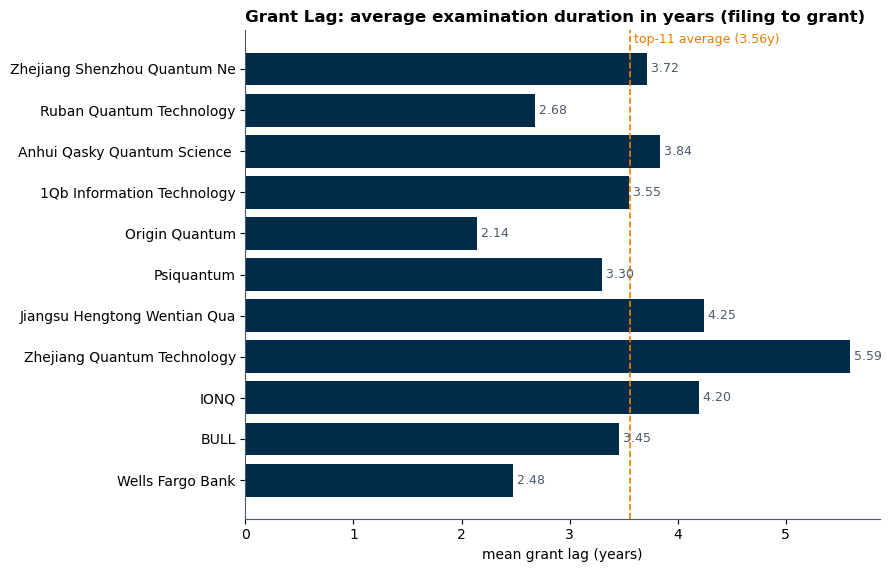

In [117]:
q_lag = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_filing_date,
        TLS211_PAT_PUBLN.publn_date,
        TLS201_APPLN.granted
    )
    .join(TLS211_PAT_PUBLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
    .filter(TLS201_APPLN.granted == "Y")
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
    .filter(TLS211_PAT_PUBLN.publn_first_grant == "Y")
)
lag_df = patstat.df(q_lag).drop_duplicates("appln_id")

lag_df["appln_filing_date"] = pd.to_datetime(lag_df["appln_filing_date"], errors="coerce")
lag_df["publn_date"] = pd.to_datetime(lag_df["publn_date"], errors="coerce")
lag_df["grant_lag_years"] = (lag_df["publn_date"] - lag_df["appln_filing_date"]).dt.days / 365.25

valid_lag = lag_df[(lag_df["grant_lag_years"] >= 0) & (lag_df["grant_lag_years"] <= 20)]

family_lag = valid_lag.groupby("docdb_family_id")["grant_lag_years"].mean()
families["family_lag"] = families.docdb_family_id.map(family_lag)

lag_firm = per_firm("family_lag").rename("grant_lag")

firm_bars(
    lag_firm, 
    "Grant Lag: average examination duration in years (filing to grant)", 
    "mean grant lag (years)", 
    ref=lag_firm.mean(), 
    ref_label=f"top-11 average ({lag_firm.mean():.2f}y)"
)

* Across the 11 selected firms, the mean grant lag is **3.56 years**. This is an exploratory diagnostic and is not part of the final composite score. *(Methodological note: `grant_lag` is an exploratory diagnostic and is excluded from the final composite score; consistent with the incumbent benchmark pipeline, the reference line reflects the unweighted mean across the top 11 firms rather than the full sector universe, and retains all granted family members in `TLS201`.)*
* **Origin Quantum** has the shortest average lag (**2.14 years**), followed by Wells Fargo Bank (**2.48**) and Ruban Quantum Technology (**2.68**). PsiQuantum (**3.30**), BULL (**3.45**) and 1Qb (**3.55**) are close to the group reference.
* The longest lags are recorded by **Zhejiang Quantum Technology (5.59 years)** and **Jiangsu Hengtong Wentian (4.25 years)**, followed by **IonQ (4.20 years)**. Anhui Qasky (**3.84**) and Zhejiang Shenzhou (**3.72**) are also above the mean.
* Grant lag should not be interpreted as a direct measure of patent quality or examination difficulty: it can also reflect office-specific procedures, prosecution strategy, filing geography and the mix of applications in each portfolio.

### 6.4 Refinement: Number of Claims (Legal Scope)

The **number of claims** in a patent sets its legal boundary of protection. More claims generally mean a broader legal scope, offering multiple fallback positions and more ways to block imitators in the market. 

While applicants often try to balance breadth with clarity, a rich claim structure signals a well-protected invention and a strong strategic effort to secure commercial exclusivity across various facets of the technology.
* **Watch out:** Some applicants inflate claims for strategic reasons.

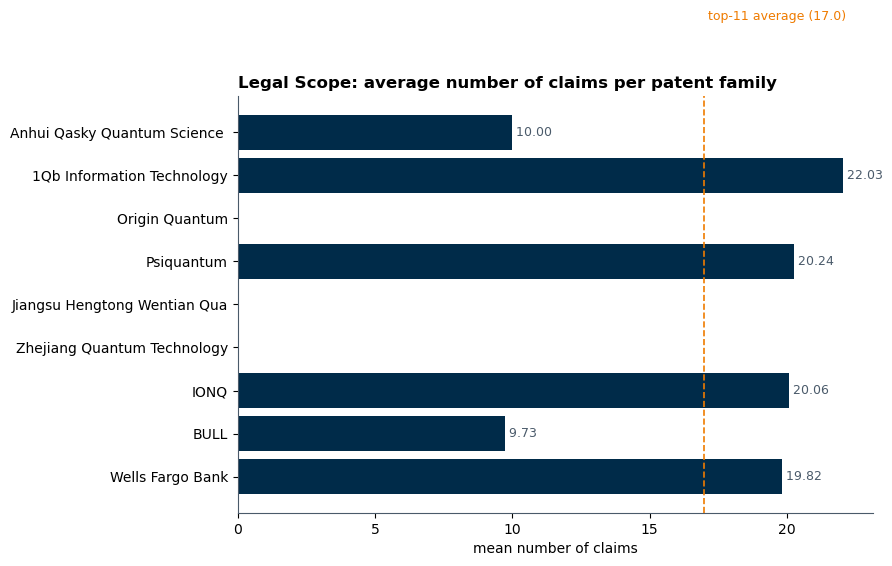

,6.1 global apps,6.2 family-level,6.3 grant lag (yrs),6.4 claims scope
firm,,,,
Zhejiang Shenzhou Quantum Ne,0.69,0.69,3.72,NaN
Ruban Quantum Technology,0.75,0.75,2.68,NaN
Anhui Qasky Quantum Science,0.68,0.59,3.84,10.00
1Qb Information Technology,0.77,0.71,3.55,22.03
Origin Quantum,0.82,0.83,2.14,NaN
Psiquantum,0.83,0.84,3.30,20.24
Jiangsu Hengtong Wentian Qua,0.47,0.47,4.25,NaN
Zhejiang Quantum Technology,0.58,0.58,5.59,NaN
IONQ,0.89,0.89,4.20,20.06


In [118]:
q_claims = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS211_PAT_PUBLN.publn_claims
    )
    .join(TLS211_PAT_PUBLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
)
claims_df = patstat.df(q_claims).drop_duplicates("appln_id")

claims_df["publn_claims"] = pd.to_numeric(claims_df["publn_claims"], errors="coerce").fillna(0)

family_claims = claims_df[claims_df["publn_claims"] > 0].groupby("docdb_family_id")["publn_claims"].mean()
families["family_claims"] = families.docdb_family_id.map(family_claims)

claims_firm = per_firm("family_claims").rename("number_of_claims")

firm_bars(
    claims_firm, 
    "Legal Scope: average number of claims per patent family", 
    "mean number of claims", 
    ref=claims_firm.mean(), 
    ref_label=f"top-11 average ({claims_firm.mean():.1f})"
)

pd.concat([success_global, family_success, lag_firm, claims_firm], axis=1) \
  .rename(columns={
      "success_global": "6.1 global apps", 
      "family_success": "6.2 family-level",
      "grant_lag": "6.3 grant lag (yrs)",
      "number_of_claims": "6.4 claims scope"
  }) \
  .rename(index=SHORT) \
  .round(2)

* Claim-count metadata are unavailable for five firms in this output: **Zhejiang Shenzhou, Ruban Quantum Technology, Origin Quantum, Jiangsu Hengtong Wentian and Zhejiang Quantum Technology**. Their values are `NaN`, not zero, so they should not be ranked on this indicator.
* Among the firms with recorded values, **1Qb Information Technology** has the highest mean (**22.03 claims per family**), followed by **PsiQuantum (20.24)**, **IonQ (20.06)** and **Wells Fargo Bank (19.82)**. The plotted reference across the selected firms with available data is **17.0**.
* **Anhui Qasky** averages **10.00** claims per family, while **BULL** averages **9.73**. These values are below the reference, but claim counts alone do not establish the breadth, strength or commercial value of the claims.

The missing values are a data-availability limitation, not evidence that those firms' patents have no claims.

## 7. Globalization: breadth of market protection

Protecting the same invention in many countries is expensive (attorneys, translations, fees at every office and then renewals every year), so a firm extends a family abroad only when it expects the invention to be worth it on those markets (lecture, *Family size*). For our client this is also a very concrete question: a patent protects only where it is in force, so a portfolio filed only at home is worth little on the markets where Dell actually sells servers and storage.

In our sector we expect this dimension to separate the firms a lot. In Step 1 we found 1.89 applications per family in 2022 against 1.47 for patenting as a whole, but also that the quantum communication block is full of single-office filings at CNIPA (`docs/appropriability.md`). So we expect two groups: firms that file worldwide and firms that file only in their home market.

### 7.1 Basics: offices per family

For each family we count the distinct offices (`appln_auth`) of its applications, at any office:

- we use the same `national` applications of section 6: no `WO` (a PCT request is not protection anywhere yet) and no kind `T` (translations of granted EP patents: they are the EP patent validated in a country, and refinement 7.2 counts them properly);
- `EP` counts as **one** office here; refinement 7.2 opens it up into states;
- a family with a PCT request and no national application yet counts as 1 office, as in the tutorial.

$$\text{Globalization}_f=\text{mean number of distinct offices per family of firm } f$$

Share of the sector's families filed at each office (the 10 most frequent):
appln_auth
CN    52.0%
US    51.5%
EP    20.5%
JP    16.6%
KR    10.9%
CA     7.4%
AU     4.8%
GB     4.5%
DE     2.5%
ES     2.1%


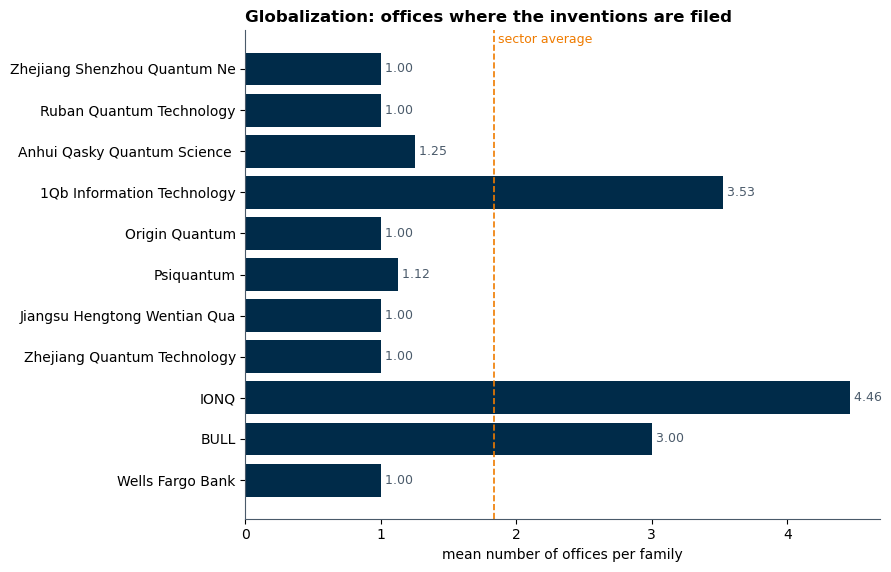

In [119]:
families["offices"] = families.docdb_family_id.map(national.groupby("docdb_family_id").appln_auth.nunique()).fillna(1)
globalization = per_firm("offices").rename("globalization")

reach = national.drop_duplicates(["docdb_family_id", "appln_auth"]).appln_auth.value_counts() / len(families)
print("Share of the sector's families filed at each office (the 10 most frequent):")
print((reach.head(10) * 100).round(1).astype(str).add("%").to_string())

firm_bars(globalization, "Globalization: offices where the inventions are filed",
          "mean number of offices per family", ref=families.offices.mean(), ref_label="sector average")

A mean can hide very different shapes: a firm with half of its families at one office and half at eight offices has the same mean (4.5) as a firm with every family at four or five offices. So next to the mean we look at the median and at the share of families filed at **one office only**, the families that the firm decided not to protect abroad at all.

In [125]:
families["single_office"] = (families.offices == 1).astype(int)
pd.concat([globalization.rename("mean offices"),
           per_firm("offices", "median").rename("median offices"),
           per_firm("single_office").rename("share at one office only")], axis=1).rename(index=SHORT).round(2)

,mean offices,median offices,share at one office only
firm,,,
Zhejiang Shenzhou Quantum Ne,1.00,1.0,1.00
Ruban Quantum Technology,1.00,1.0,1.00
Anhui Qasky Quantum Science,1.25,1.0,0.94
1Qb Information Technology,3.53,4.0,0.22
Origin Quantum,1.00,1.0,1.00
Psiquantum,1.12,1.0,0.88
Jiangsu Hengtong Wentian Qua,1.00,1.0,1.00
Zhejiang Quantum Technology,1.00,1.0,1.00
IONQ,4.46,5.0,0.31


* Patent families in the sector are most frequently filed at **CN (52.0%)** and **US (51.5%)**, followed by **EP (20.5%)**, **JP (16.6%)** and **KR (10.9%)**. These office shares overlap because one family can be filed in several jurisdictions.
* **IonQ** has the broadest international reach, with an average of **4.46 offices per family** (median 5.0); only **31%** of its families are filed at a single office. **1Qb Information Technology** follows with **3.53 offices on average** (median 4.0) and a single-office share of **22%**. **BULL** records **3.00 offices on average** (median 3.0), and none of its families is limited to a single office.
* The remaining firms show substantially more concentrated filing strategies. **Anhui Qasky Quantum Science** averages **1.25 offices per family**, but its median is 1.0 and **94%** of its families are filed at one office only. **PsiQuantum** averages **1.12 offices** (median 1.0), with **88%** of families at a single office.
**Zhejiang Shenzhou Quantum Ne**, **Ruban Quantum Technology**, **Origin Quantum**, **Jiangsu Hengtong Wentian Qua**, **Zhejiang Quantum Technology** and **Wells Fargo Bank** each record **1.00 office per family** on average; their median is also 1.0 and **100%** of their families are single-office. This points to portfolios concentrated in one filing jurisdiction rather than broad geographic protection.

### 7.2 Refinement: in which European states are the EP patents validated?

A granted EP patent is not yet protection anywhere: the owner must **validate** it in each state where it wants protection (translations, fees), and then pay a **renewal** fee every year in each of them. The number of states is a strong signal of how much the owner values the patent, because each state costs money every year.

PATSTAT has this in the **legal events** (`TLS231`), not in `TLS201`. Three event codes describe the life of an EP patent in each state:

| Code | Meaning | Country in |
|---|---|---|
| `PGFP` | annual fee paid to a national office: the patent is (or was) valid there | `fee_country` |
| `VSFP` | annual fee paid to a **validation state** outside the EPC (e.g. Morocco) | `fee_country` |
| `PG25` | patent **lapsed** in a state, with the reason in `lapse_text` | `lapse_country` |

As in the tutorial, a `PG25` counts as validated only if the reason is *non-payment of due fees* (the patent was valid, then the owner stopped paying); a lapse for *failure to submit a translation* means the owner never validated it there.

**Difference with the tutorial.** There every family had an EP application, because the sample was built at the EPO. Our sector is built at **all** offices, so this refinement only reads the families that went to Europe and got the grant. Before using it we print how many they are: if only a small part of a firm's portfolio has a granted EP patent, its number of states describes a few families, not the firm.

In [120]:
ep = members[members.appln_auth == "EP"].copy()
ep_granted = [int(i) for i in ep.loc[ep.granted == "Y", "appln_id"]]
print(f"Families with an EP application: {ep.docdb_family_id.nunique():,} of {len(families):,} "
      f"({ep.docdb_family_id.nunique() / len(families):.0%}); granted EP applications: {len(ep_granted):,}")

q = (
    db.query(TLS231_INPADOC_LEGAL_EVENT.appln_id, TLS231_INPADOC_LEGAL_EVENT.event_code,
             TLS231_INPADOC_LEGAL_EVENT.fee_country, TLS231_INPADOC_LEGAL_EVENT.lapse_country,
             TLS231_INPADOC_LEGAL_EVENT.lapse_text)
    .filter(TLS231_INPADOC_LEGAL_EVENT.appln_id.in_(ep_granted))
    .filter(TLS231_INPADOC_LEGAL_EVENT.event_code.in_(["PGFP", "VSFP", "PG25"]))
)
events_val = patstat.df(q)
events_val["lapse_text"] = events_val.lapse_text.fillna("").str.upper()
print("\nEvents by code:", events_val.event_code.value_counts().to_dict())
print("\nReasons of the PG25 lapses:")
print(events_val[events_val.event_code == "PG25"].lapse_text.str[:70].value_counts().head(5).to_string())

# validated = fee paid (PGFP, VSFP), or lapsed for non-payment after being valid (PG25 + NON-PAYMENT)
lapsed_after_valid = (events_val.event_code == "PG25") & events_val.lapse_text.str.contains("NON-PAYMENT")
val = events_val[events_val.event_code.isin(["PGFP", "VSFP"]) | lapsed_after_valid].copy()
val["country"] = np.where(val.event_code == "PG25", val.lapse_country, val.fee_country)
val["country"] = val.country.fillna("").str.strip()
val = val[(val.country != "") & (val.country != "EP")].drop_duplicates(["appln_id", "country"])

Families with an EP application: 629 of 3,061 (21%); granted EP applications: 485

Events by code: {'PG25': 14944, 'PGFP': 1643}

Reasons of the PG25 lapses:
lapse_text
LAPSE BECAUSE OF FAILURE TO SUBMIT A TRANSLATION OF THE DESCRIPTION OR    12905
LAPSE BECAUSE OF NON-PAYMENT OF DUE FEES                                   2039


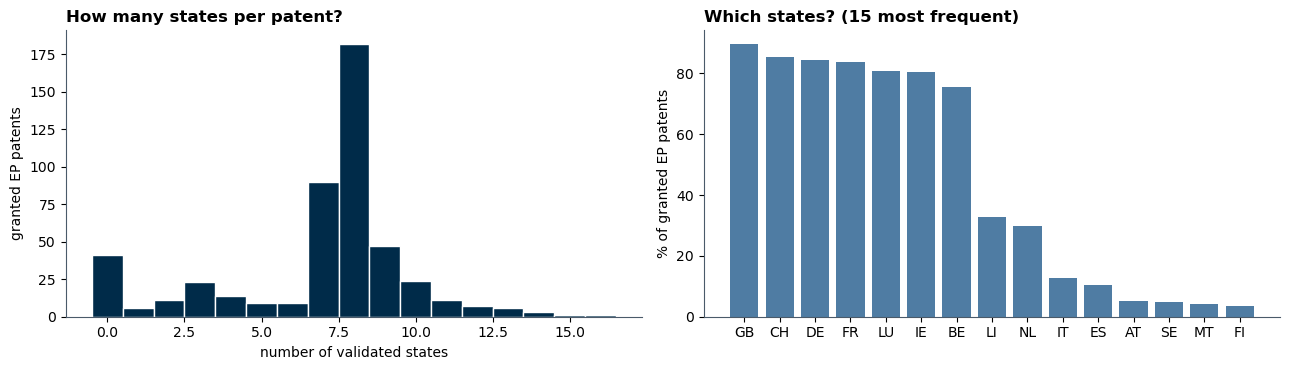

Granted EP patents with no validation event: 8%; median number of states: 8


In [121]:
states = val.groupby("appln_id").country.nunique()
n_states = pd.Series(ep_granted).map(states).fillna(0)          # granted patents with no event: 0 states
country_share = val.country.value_counts() / len(ep_granted)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(n_states, bins=range(0, int(n_states.max()) + 2), color=NAVY, edgecolor="white", align="left")
axes[0].set_xlabel("number of validated states")
axes[0].set_ylabel("granted EP patents")
axes[0].set_title("How many states per patent?")
top_states = country_share.head(15)
axes[1].bar(top_states.index, top_states.values * 100, color=BLUE)
axes[1].set_ylabel("% of granted EP patents")
axes[1].set_title("Which states? (15 most frequent)")
plt.tight_layout()
plt.show()
print(f"Granted EP patents with no validation event: {(n_states == 0).mean():.0%}; "
      f"median number of states: {n_states.median():.0f}")

The indicator for a firm is the mean number of validated states of its **granted** EP families (a family takes its best EP patent). Next to it we print how many of the firm's families have a granted EP patent at all, which tells us how much of the portfolio the number describes.

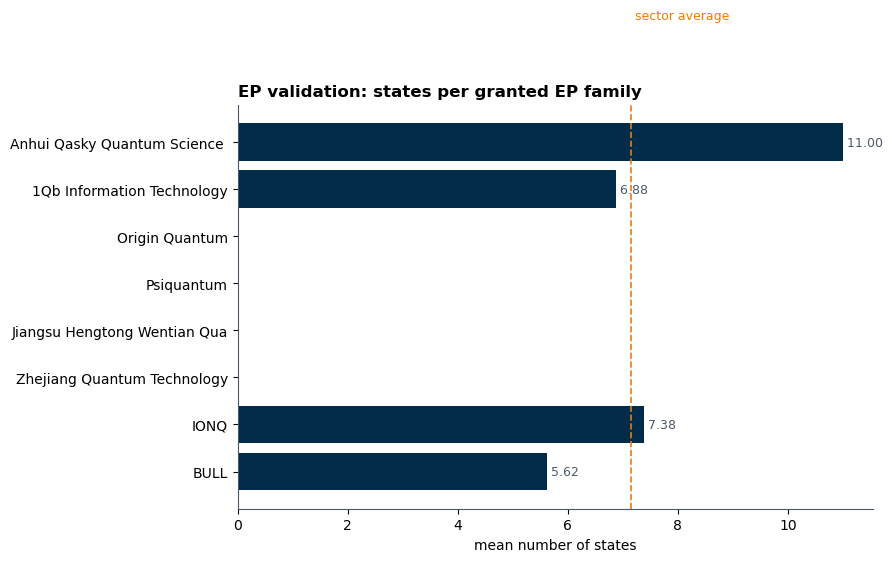

,families with a granted EP,share of the firm's families,mean states
firm,,,
Zhejiang Shenzhou Quantum Ne,0,0.00,NaN
Ruban Quantum Technology,0,0.00,NaN
Anhui Qasky Quantum Science,2,0.06,11.00
1Qb Information Technology,8,0.22,6.88
Origin Quantum,0,0.00,NaN
Psiquantum,0,0.00,NaN
Jiangsu Hengtong Wentian Qua,0,0.00,NaN
Zhejiang Quantum Technology,0,0.00,NaN
IONQ,8,0.62,7.38


In [122]:
ep_g = ep[ep.granted == "Y"].copy()
ep_g["states"] = ep_g.appln_id.map(states).fillna(0)
families["ep_states"] = families.docdb_family_id.map(ep_g.groupby("docdb_family_id").states.max())
families["ep_granted"] = families.docdb_family_id.isin(ep_g.docdb_family_id).astype(int)
ep_states = per_firm("ep_states")
ep_reach = per_firm("ep_granted").rename("granted_ep_share")

firm_bars(ep_states, "EP validation: states per granted EP family", "mean number of states",
          ref=families.ep_states.mean(), ref_label="sector average")
pd.concat([per_firm("ep_granted", "sum").rename("families with a granted EP"),
           ep_reach.rename("share of the firm's families"), ep_states.rename("mean states")],
          axis=1).rename(index=SHORT).round(2)

* **629 of 3,061 families (21%)** have an EP application, and the data contain **485 granted EP applications**. Among granted EP patents, the median number of validated states is **8**; **8%** have no validation event recorded.
* The country chart shows the highest validation frequencies in **GB, CH, DE, FR, LU, IE and BE** (roughly **75%–90%** of granted EP patents). The shares then fall markedly: LI and NL are around 30%, IT and ES around 10%–13%, with the remaining displayed states lower.
* Seven firms have no families with a granted EP patent in this window: Zhejiang Shenzhou, Ruban, Origin Quantum, PsiQuantum, Jiangsu Hengtong, Zhejiang Quantum Technology and Wells Fargo Bank. Their mean validated-state values are therefore missing, not zero.
* **IonQ** and **1Qb Information Technology** each have **8** families with a granted EP patent. These represent **62%** of IonQ's portfolio and **22%** of 1Qb's; their mean numbers of validated states are **7.38** and **6.88**, respectively.
* **BULL** also has **8** granted-EP families (**67%** of its portfolio), with a mean of **5.62** states. **Anhui Qasky** has **2** such families (**6%** of its portfolio), averaging **11.00** states. That high mean is based on only two families and should be interpreted cautiously.

### 7.3 Refinement: quadrilateral families, the Clarivate measure

Counting offices treats every office the same: Australia counts as much as the United States. Clarivate looks instead at the **four main markets**, the offices of China (CN), Europe (EP), Japan (JP) and the United States (US). A **quadrilateral family** is filed at all four: an expensive choice, made only for inventions with a global market.

$$\text{Quadrilateral share}_f=\frac{\text{families of } f \text{ filed at CN, EP, JP and US}}{\text{families of } f}$$

Two differences with the tutorial. First, our families do not all have an EP application, so a family must reach **all four** offices, EP included. Second, being 0/1 the quadrilateral share is harsh: a family filed at US, EP and CN but not JP counts as 0, like a family filed only in China. So we also compute a softer version on the **IP5 offices** we already used in Step 1 (CN, EP, JP, KR, US, from `sector.yaml`): the mean number of IP5 offices reached per family, from 0 to 5.

Quadrilateral families in the sector: 7%; mean IP5 offices per family: 1.52


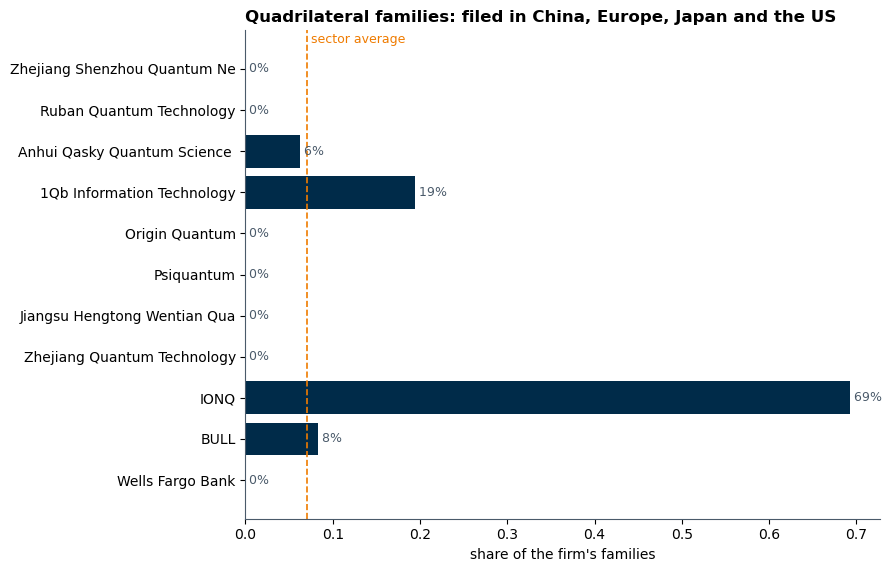

,quadrilateral_share,ip5_offices
firm,,
Zhejiang Shenzhou Quantum Ne,0.00,1.00
Ruban Quantum Technology,0.00,1.00
Anhui Qasky Quantum Science,0.06,1.19
1Qb Information Technology,0.19,2.44
Origin Quantum,0.00,1.00
Psiquantum,0.00,0.94
Jiangsu Hengtong Wentian Qua,0.00,1.00
Zhejiang Quantum Technology,0.00,0.92
IONQ,0.69,3.23


In [123]:
QUAD = {"CN", "EP", "JP", "US"}
IP5 = set(cfg.ip5_offices)                      # CN, EP, JP, KR, US

offices_of = national.groupby("docdb_family_id").appln_auth.agg(set)
families["quadrilateral"] = families.docdb_family_id.map(lambda f: QUAD <= offices_of.get(f, set())).astype(int)
families["ip5_offices"] = families.docdb_family_id.map(lambda f: len(IP5 & offices_of.get(f, set())))
quadrilateral_share = per_firm("quadrilateral").rename("quadrilateral_share")
ip5_reach = per_firm("ip5_offices").rename("ip5_offices")

print(f"Quadrilateral families in the sector: {families.quadrilateral.mean():.0%}; "
      f"mean IP5 offices per family: {families.ip5_offices.mean():.2f}")
firm_bars(quadrilateral_share, "Quadrilateral families: filed in China, Europe, Japan and the US",
          "share of the firm's families", fmt="{:.0%}", ref=families.quadrilateral.mean(), ref_label="sector average")
pd.concat([quadrilateral_share, ip5_reach], axis=1).rename(index=SHORT).round(2)

* Across the sector, **7%** of families are quadrilateral, meaning they are filed in all four offices **CN, EP, JP and US**. The average family reaches **1.52 IP5 offices**.
* **IonQ** is the clear leader: **69%** of its families are quadrilateral and it reaches **3.23 IP5 offices per family** on average.
* **1Qb Information Technology** follows with **19%** quadrilateral families and **2.44** IP5 offices per family. **BULL** records **8%** and **2.08**; **Anhui Qasky** records **6%** and **1.19**.
* The other firms have no quadrilateral families in this sample. Their mean IP5 reach is **1.00** for Zhejiang Shenzhou, Ruban, Origin Quantum, Jiangsu Hengtong and Wells Fargo Bank, and slightly below one for PsiQuantum (**0.94**) and Zhejiang Quantum Technology (**0.92**).
* The comparison illustrates why the quadrilateral indicator is demanding: a family must reach all four major offices to count, while the IP5 mean also gives credit to families that reach only a subset.

### 7.4 Refinement: protection outside the home market

Every count above includes the **home office**, which is the cheapest and the most obvious one: a Chinese firm filing at CNIPA or an American firm filing at the USPTO is not yet "going global". What really costs, and what really signals value, is the decision to protect the invention **abroad**. This matters in our sector and Step 1 already suggested that a good part of the Chinese activity is filed only at CNIPA.

For each (family, firm) pair, the family is protected abroad if it has at least one national application at an office outside the firm's **home market**:

- the home country is the `ctry` given to the applicant by the harmonisation of Step 2 (`prepare_applicants`, the most frequent country of the applicant);
- for a firm of an EPC member state, the EPO is also home: a German firm filing at DE and EP has not left Europe.

$$\text{Foreign reach}_f=\frac{\text{families of } f \text{ filed at least at one office outside its home market}}{\text{families of } f}$$

It is computed per (family, firm) and not per family, because a co-owned family can be "home" for one owner and "abroad" for the other.

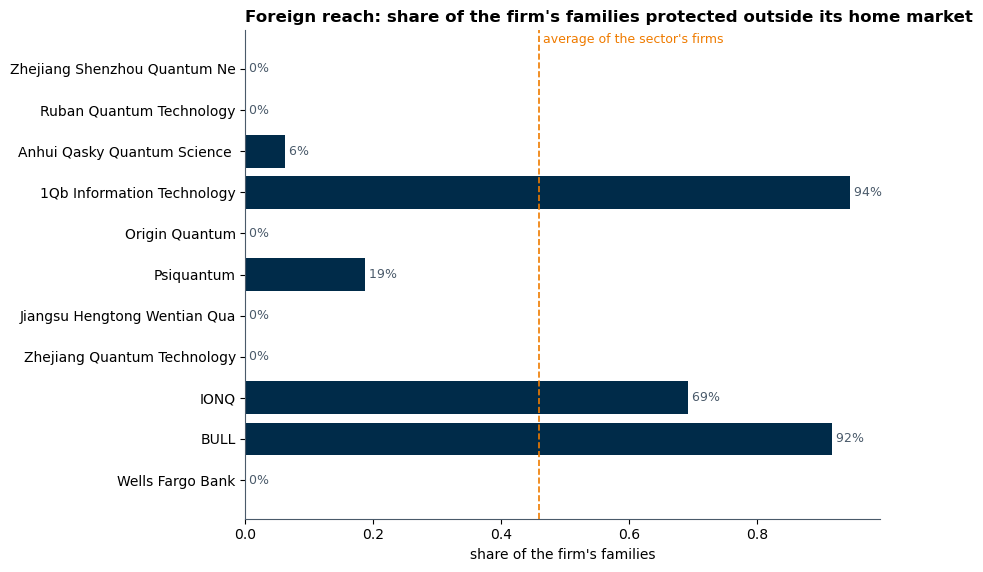

,home,foreign_share
firm,,
Zhejiang Shenzhou Quantum Ne,CN,0.00
Ruban Quantum Technology,CN,0.00
Anhui Qasky Quantum Science,CN,0.06
1Qb Information Technology,CA,0.94
Origin Quantum,CN,0.00
Psiquantum,US,0.19
Jiangsu Hengtong Wentian Qua,CN,0.00
Zhejiang Quantum Technology,CN,0.00
IONQ,US,0.69


In [124]:
EPC_STATES = {"AL", "AT", "BE", "BG", "CH", "CY", "CZ", "DE", "DK", "EE", "ES", "FI", "FR", "GB", "GR", "HR",
              "HU", "IE", "IS", "IT", "LI", "LT", "LU", "LV", "MC", "ME", "MK", "MT", "NL", "NO", "PL", "PT",
              "RO", "RS", "SE", "SI", "SK", "SM", "TR"}


def home_offices(ctry):
    "The offices that count as the home market of an applicant of country ctry."
    return {ctry, "EP"} if ctry in EPC_STATES else {ctry}


firm_home = fam_firm.dropna(subset=["ctry"]).groupby("firm").ctry.agg(lambda c: c.mode().iat[0])

# firms with no country in TLS206: home = the office where the firm files most often
members_firm = national.merge(fam_firm[["docdb_family_id", "firm"]].drop_duplicates(), on="docdb_family_id")
office_mode = members_firm.groupby("firm").appln_auth.agg(lambda a: a.mode().iat[0])
firm_home = firm_home.combine_first(office_mode)

abroad = fam_firm[["docdb_family_id", "firm"]].copy()
abroad["home"] = abroad.firm.map(firm_home)
abroad = abroad.dropna(subset=["home"])
abroad["abroad"] = [int(len(offices_of.get(f, set()) - home_offices(h)) > 0)
                    for f, h in zip(abroad.docdb_family_id, abroad.home)]
foreign_share = abroad.groupby("firm").abroad.mean().reindex(TOP).rename("foreign_share")

firm_bars(foreign_share, "Foreign reach: share of the firm's families protected outside its home market",
          "share of the firm's families", fmt="{:.0%}", ref=abroad.abroad.mean(),
          ref_label="average of the sector's firms")
pd.concat([firm_home.reindex(TOP).rename("home"), foreign_share], axis=1).rename(index=SHORT).round(2)

* The foreign-reach chart uses the firm's home market as the baseline. **1Qb Information Technology** has the highest foreign reach (**94%**, home market **CA**), followed by **BULL (92%, FR)** and **IonQ (69%, US)**. These are the only firms above the sector-firm reference line (approximately **56%**).
* **PsiQuantum** records **19%** foreign reach from a US home market. **Anhui Qasky** records **6%** from China.
* Zhejiang Shenzhou, Ruban, Origin Quantum, Jiangsu Hengtong and Zhejiang Quantum Technology each record **0%** foreign reach from a Chinese home market. **Wells Fargo Bank** also records **0%** from a US home market.
* The results show a marked contrast between the internationally oriented portfolios of 1Qb, BULL and IonQ and the predominantly domestic portfolios of several other firms. A zero value means no family in the analysed portfolio is recorded as protected outside the defined home market; it does not mean that the firm has no patents.